<a href="https://colab.research.google.com/github/ekee7/cuisine-and-commerce/blob/main/Cuisine_and_Coordinates_Exploring_and_Predicting_NYC_Restaurant_Inspection_Outcomes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cuisine and Coordinates: Exploring and Predicting NYC Restaurant Inspection Outcomes

### Group Members:
Emma Kee, KS, SL, HM, SM

(Other group members’ names have been abbreviated to initials for privacy)

## Research Question & Data Set Recap:
Our project investigates how cuisine type and restaurant location relate to health inspection outcomes in New York City, and whether inspection scores can be predicted using these restaurant characteristics.

We use the New York City Restaurant Inspection dataset from NYC Open Data, provided by the Department of Health and Mental Hygiene (DOHMH), which contains over 296,000 observations where each row represents a single restaurant inspection with information on restaurant attributes, inspection details, and violations. The outcome variable in our analysis is the inspection score, a non-negative integer summarizing the severity of violations found during an inspection (lower scores indicate better performance).

Our predictor features focus primarily on location variables such as borough, ZIP code, latitude, and longitude, as well as restaurant characteristics such as cuisine type. Using these variables, we aim to examine how cuisine and location relate to inspection outcomes and to develop a model that predicts variation in restaurant food safety performance across New York City.



## Data Wrangling (SM):

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

**Loading Data**

The API endpoint URL to directly download the data could not be used, since it has a limit of only 1000 rows. Therefore, we have downloaded the data as a .csv file and loading it from Google Drive.

Click on the link to add the folder to your Google Drive, which contains the .csv file. After clicking on the link, you can click on the folder name > Organize > Add Shortcut, and then add it to 'My Drive'.

https://drive.google.com/drive/folders/1p1OVnzROJleLU7W-znfYhxBuRedYjjaT?usp=sharing

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.chdir('/content/drive/MyDrive/DS-3001/DS_3001_Project')
#os.chdir('/content/drive/MyDrive/DS_3001_Project')
#os.chdir('/content/drive/MyDrive/DS3001')

In [ ]:
os.getcwd()

'/content/drive/.shortcut-targets-by-id/1p1OVnzROJleLU7W-znfYhxBuRedYjjaT/DS_3001_Project'

In [ ]:
df = pd.read_csv('DOHMH_New_York_City_Restaurant_Inspection_Results_20260312.csv')
# df = pd.read_csv('DOHMH_New_York_City_Restaurant_Inspection_Results_20260314.csv')

In [ ]:
# Briefly inspect the dataset
df.head()

,CAMIS,DBA,BORO,BUILDING,STREET,ZIPCODE,PHONE,CUISINE DESCRIPTION,INSPECTION DATE,ACTION,...,INSPECTION TYPE,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA,Location
0,50180416,CASA DEL SAZON DOMINICANO LLC,Bronx,906,EAST 180 STREET,10460.0,3475097761,NaN,01/01/1900,NaN,...,NaN,40.844789,-73.882075,206.0,15.0,36300.0,2114808.0,2.031220e+09,BX17,POINT (-73.882074928285 40.844788884336)
1,50156723,CHROME 101,Queens,96-03,101 AVENUE,11416.0,7186696506,NaN,01/01/1900,NaN,...,NaN,40.684610,-73.844807,409.0,32.0,3800.0,4188650.0,4.090710e+09,QN53,POINT (-73.844806675221 40.684609758921)
2,50150804,SOLEIL BRASSERIE (CONNECTOR LEVEL),Queens,LAGUARDIA,AIRPORT,11369.0,2159970667,NaN,01/01/1900,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,50167960,NEUHAUS INC,Manhattan,4,PENN PLAZA,10121.0,6466413694,NaN,01/01/1900,NaN,...,NaN,40.750655,-73.991944,105.0,3.0,10100.0,1082908.0,1.007810e+09,MN17,POINT (-73.991944239076 40.750654836632)
4,50180148,EL MEXICANO RESTAURANTE & CAFFEE 2 CORPORATION,Brooklyn,310,DITMAS AVENUE,11218.0,6468361743,NaN,01/01/1900,NaN,...,NaN,40.635787,-73.975756,312.0,40.0,48400.0,3127092.0,3.053970e+09,BK41,POINT (-73.975755579098 40.635786572236)


**Inspect dataset structure and raw data types**

We look at the shape, data types and column names of the dataset to verify if the data types match the expected types for each column, and make sure each column in the dataset is a variable.

The dataset has 297028 rows (instances) and 27 columns (variables)

The variables with inconsistent types are ZIP code (float should be object), inspection date, grade date, record date (should be datetime objects), BIN and BBL (floats should be objects). This is important to identify because incorrect types can lead to errors in feature engineering and calculations.

In [ ]:
print('Shape of the data (rows, columns):\n', df.shape, '\n') # List the dimensions of df
print('Data Type of Each Column:\n', df.dtypes, '\n') # The types of the variables
print('Column Names:\n', df.columns, '\n') # Column names

Shape of the data (rows, columns):
 (297028, 27) 

Data Type of Each Column:
 CAMIS                      int64
DBA                       object
BORO                      object
BUILDING                  object
STREET                    object
ZIPCODE                  float64
PHONE                     object
CUISINE DESCRIPTION       object
INSPECTION DATE           object
ACTION                    object
VIOLATION CODE            object
VIOLATION DESCRIPTION     object
CRITICAL FLAG             object
SCORE                    float64
GRADE                     object
GRADE DATE                object
RECORD DATE               object
INSPECTION TYPE           object
Latitude                 float64
Longitude                float64
Community Board          float64
Council District         float64
Census Tract             float64
BIN                      float64
BBL                      float64
NTA                       object
Location                  object
dtype: object 

Column Names:
 

Look at the values of the ZIP code variable. They are float (decimal numbers),which needs to be changed, since ZIP codes in the real world work as geographic identifiers instead of a numeric quantity.

In [ ]:
df['ZIPCODE']

,ZIPCODE
0,10460.0
1,11416.0
2,11369.0
3,10121.0
4,11218.0
...,...
297023,11224.0
297024,11212.0
297025,11415.0
297026,11101.0


Convert ZIP code to a string. This also helps us preserve leading zeroes, which are present in some ZIP codes. This conversion prevents the model from interpreting it as a continuous numeric feature when it's not.

In [ ]:
# Remove decimal part by converting to int, then convert to string
df['ZIPCODE'] = df['ZIPCODE'].astype('Int64').astype(str)
# Restore any leading zeroes that were cut off when converting to int
# Zipcodes are 5 digits, so the ones shorter than 5 are the ones that need to be filled)
df['ZIPCODE'] = df['ZIPCODE'].str.zfill(5)
print("Zipcode column after cleaning:\n", df['ZIPCODE'])

Zipcode column after cleaning:
 0         10460
1         11416
2         11369
3         10121
4         11218
          ...  
297023    11224
297024    11212
297025    11415
297026    11101
297027    10017
Name: ZIPCODE, Length: 297028, dtype: object


Convert inspection date, grade date, and record date to datetime objects. We do this so we can correctly filter by time and create date-based features (like month and day) during feature engineering.

In [ ]:
df['INSPECTION DATE'] = pd.to_datetime(df['INSPECTION DATE'])
df['GRADE DATE'] = pd.to_datetime(df['GRADE DATE'])
df['RECORD DATE'] = pd.to_datetime(df['RECORD DATE'])

# Confirm conversion
print('Inspection date data type after converting:', df['INSPECTION DATE'] .dtype, '\n')
print('Grade date data type after converting:', df['GRADE DATE'] .dtype, '\n')
print('Record date data type after converting:', df['RECORD DATE'] .dtype, '\n')

Inspection date data type after converting: datetime64[ns] 

Grade date data type after converting: datetime64[ns] 

Record date data type after converting: datetime64[ns] 



Convert identifier columns to strings: BIN (binary identification number), BBL (borough-block-lot identifier) are identifiers rather than continuous numeric variables. So for the same reason that the ZIP code was converted to a string, these data types are converted to a string too.



In [ ]:
df['BIN'] = df['BIN'].astype(str)
df['BBL'] = df['BBL'].astype(str)

# Confirm conversion
print('BIN data type after converting:', df['BIN'].dtype, '\n')
print('BBL data type after converting:', df['BBL'].dtype, '\n')

BIN data type after converting: object 

BBL data type after converting: object 



**Evaluate location-based features based on cardinality**

We run the value counts for location-based features: community board, council district, census tract, and NTA (stands for neighborhood tabulation area).

Features with a very high cardinality (too many rare values) can make the model more complicated without being much of a help for generalizing results. Also, for categorical variables (which all of these are), we need to one-hot encode them, and for variables with a very high cardinality, too many columns will be created in one-hot encoding. If the number of columns exceeds the number of rows, this could cause the problem to be undetermined.

In [ ]:
location_cols = ['Community Board', 'Council District', 'Census Tract', 'NTA']

# Look at the value counts for each unique value in the column
for col in location_cols:
  print(f"\nValue counts for {col}:")
  print(df[col].value_counts())


Value counts for Community Board:
Community Board
105.0    23081
103.0    14680
102.0    13491
407.0    11962
104.0    11347
         ...  
228.0       23
480.0       17
482.0        6
226.0        6
595.0        5
Name: count, Length: 69, dtype: int64

Value counts for Council District:
Council District
3.0     24563
1.0     21582
4.0     20510
2.0     15028
20.0     9602
33.0     9140
34.0     8650
26.0     8372
22.0     7859
39.0     7307
25.0     6923
43.0     6337
38.0     6074
35.0     6048
6.0      6046
5.0      5687
21.0     5287
29.0     5002
19.0     4990
7.0      4498
8.0      4462
10.0     4391
40.0     4358
36.0     4251
27.0     4058
30.0     4030
48.0     3896
47.0     3820
11.0     3813
15.0     3677
13.0     3658
32.0     3654
50.0     3582
49.0     3536
37.0     3504
17.0     3396
24.0     3322
23.0     3306
28.0     3133
46.0     2938
45.0     2926
51.0     2903
41.0     2898
9.0      2860
12.0     2708
18.0     2706
14.0     2694
44.0     2486
16.0     2173
42.0   

The conclusion from this was to drop the census tract and NTA, since their cardinalities were relatively high (with values 1182 and 193, respectively).

**Drop unwanted features**

We removed columns that are irrelevant to predicting restaurant violations (our research question), redundant, or would introduce target leakage. The reasons for dropping the features we did are here below:

- DBA (doing business as, essentially the restaurant name) has a very high cardinality, and restaurants are uniquely identified by their CAMIS ID (City-owned Applications Management Information System ID).
- Phone (number) is irrelevant to predicting restaurant violations. Dropping it saves space in the Dataframe.
- Grade is a processed value from score, so it would cause target leakage. It would be bad for the model's accuracy for the test set to be learning from values that would not be available at prediction time. Since Grade was dropped, Grade Date was dropped too.
- Record date is the date the dataset was last updated, which is daily, and same for all instances, so we are dropping it since does not provide any distinct information about each instance that the model could learn from.
- BIN was dropped since all instances can already be identified by their CAMIS ID, so it was redundant to the CAMIS feature.

In [ ]:
to_drop = ['DBA', 'PHONE', 'BUILDING', 'STREET', 'Location','GRADE','GRADE DATE', 'RECORD DATE', 'BIN', 'Census Tract', 'NTA']
df = df.drop(columns=to_drop, errors='ignore')

Confirm that the features have been dropped by running df.info().

Through this, we can also see that each row represents the same type of observations (all rows have a CAMIS, so they are all restaurants).

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297028 entries, 0 to 297027
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   CAMIS                  297028 non-null  int64         
 1   BORO                   297028 non-null  object        
 2   ZIPCODE                297028 non-null  object        
 3   CUISINE DESCRIPTION    293662 non-null  object        
 4   INSPECTION DATE        297028 non-null  datetime64[ns]
 5   ACTION                 293662 non-null  object        
 6   VIOLATION CODE         291358 non-null  object        
 7   VIOLATION DESCRIPTION  291357 non-null  object        
 8   CRITICAL FLAG          297028 non-null  object        
 9   SCORE                  280285 non-null  float64       
 10  INSPECTION TYPE        293662 non-null  object        
 11  Latitude               295433 non-null  float64       
 12  Longitude              295433 non-null  floa

**Inspect the value counts across years for the inspections**

This helps understand how much data is coming from each year, and it is very important to know that there is enough data coming from recent years. This is because if the model has data from more recent years to learn from, it will perform better on new data. We also want to see if it is feasible to exclude observations that occured before COVID, since many restaurants were affected by COVID and probably operate differently after the pandemic.

In [ ]:
df['INSPECTION DATE'].dt.year.value_counts().sort_index()

,count
INSPECTION DATE,
1900,3366
2008,6
2009,45
2010,38
2011,36
2012,54
2013,34
2014,36
2015,78


From the table above, we saw that there is enough data to only keep observations from 2022 - 2026 (post-COVID years). This was done for the model to be trained on more recent restaurant and inspection patterns.

In [ ]:
df = df[df['INSPECTION DATE'] >= '2022-01-01']

# Verify
print("oldest date:", df['INSPECTION DATE'].min(), "\nnewest date:", df['INSPECTION DATE'].max())

# Check the number of rows that exist
print("(rows, columns) after filtering by year", df.shape)

oldest date: 2022-01-03 00:00:00 
newest date: 2026-03-11 00:00:00
(rows, columns) after filtering by year (289318, 16)


**Handle missing values**

We start handling missing values by seeing how many missing values appear in each column. We want to see if we would need to impute values if a siginficant amount of values are missing, or if the number of missing values compared to the number of observations is small enough that we could just drop those observations.


We want to note that violation code, violation description, critical flag, and action are going to be used for historical variables if we feel like we need to do that to improve performance, so we are not going to worry if those values are missing for now. That is also why we did not drop these values for now, but we will when running the model without historical features (due to target leakage).

In [ ]:
# Find where the missing values are
df.isna().sum().sort_values(ascending=False)

,0
SCORE,13151
Community Board,4219
Council District,4193
VIOLATION CODE,2218
VIOLATION DESCRIPTION,2218
Latitude,1308
Longitude,1308
CAMIS,0
INSPECTION DATE,0
ACTION,0


This gets the proportion of missing values in each column, rather than the counts above.

In [ ]:
(df.isna().sum().sort_values(ascending=False) / df.shape[0]) * 100

,0
SCORE,4.545517
Community Board,1.458257
Council District,1.449270
VIOLATION CODE,0.766630
VIOLATION DESCRIPTION,0.766630
Latitude,0.452098
Longitude,0.452098
CAMIS,0.000000
INSPECTION DATE,0.000000
ACTION,0.000000


We noticed that no instances are missing a CAMIS, Inspection Date, Borough, Cuisine Description, or a ZIP Code, which is great. We decided to drop instances that are missing the score, latitude, longitude, community board, or council district, due to two reasons:

1) Based on the proportions of missing values, relatively few observations had missing values compared to the total number of observations, so we can simply drop them.
2) Since location-based features are central to our research question, imputing missing values would not be meaningful and could introduce inaccurate geographic information.

In [ ]:
print("number of instances before dropping:", df.shape[0])
df = df.dropna(subset=[
    'SCORE',
    'Latitude',
    'Longitude',
    'Community Board',
    'Council District'
])
print("number of instances after dropping:", df.shape[0])

number of instances before dropping: 289318
number of instances after dropping: 272116


**One Hot Encoding:**

We converted borough and cuisine type into dummy variables so that each category can be represented as its own binary predictor. This helps avoid the assumption that these categories have an ordinal relationship, if the values were just encoded using numbers instead of binary indicators.

In [ ]:
categorical_vars_to_encode = ['BORO', 'CUISINE DESCRIPTION']
for i, var in enumerate(categorical_vars_to_encode):

  # Create the dummies
  if i == 0:
    one_hot_encoding_mat = pd.get_dummies(df[var])
  else:
    added_columns = pd.get_dummies(df[var])
    one_hot_encoding_mat = pd.concat([one_hot_encoding_mat, added_columns], axis = 1)

one_hot_encoding_mat.head()

,Bronx,Brooklyn,Manhattan,Queens,Staten Island,Afghan,African,American,Armenian,Asian/Asian Fusion,...,Southeast Asian,Southwestern,Spanish,Steakhouse,Tapas,Tex-Mex,Thai,Turkish,Vegan,Vegetarian
11,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
92,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
110,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
126,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
saved_df = df.copy()
df = pd.concat([df.drop(columns=categorical_vars_to_encode), one_hot_encoding_mat], axis=1)

In [ ]:
df.shape

(272116, 109)

**Changing column names to be shortened/more informative:**

We renamed columns to make them more descriptive and indicative of what they actually represent. For example, CAMIS was changed to restaurant_id and BORO was changed to borough. We also wanted to have a consistent naming convention, since some features were all capitalized and some only had the first letters capital, so we made all features lowercase with underscores replacing spaces. This helps make our code more readable.

In [ ]:
df = df.rename(columns={
    'CAMIS': 'restaurant_id',
    'BORO': 'borough',
    'ZIPCODE': 'zipcode',
    'CUISINE DESCRIPTION': 'cuisine_type',
    'INSPECTION DATE': 'inspection_date',
    'SCORE': 'inspection_score',
    'Latitude': 'latitude',
    'Longitude': 'longitude',
    'Community Board': 'community_board',
    'Council District': 'council_district'
})
df.head()

,restaurant_id,zipcode,inspection_date,ACTION,VIOLATION CODE,VIOLATION DESCRIPTION,CRITICAL FLAG,inspection_score,INSPECTION TYPE,latitude,...,Southeast Asian,Southwestern,Spanish,Steakhouse,Tapas,Tex-Mex,Thai,Turkish,Vegan,Vegetarian
11,50107021,11103,2023-02-27,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Re-inspection,40.761143,...,False,False,False,False,False,False,False,False,False,False
14,50070952,11373,2023-02-02,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,4.0,Cycle Inspection / Re-inspection,40.742031,...,False,False,False,False,False,False,False,False,False,False
92,41185899,10001,2025-05-29,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Initial Inspection,40.747443,...,False,False,False,False,False,False,False,False,False,False
110,41659970,10013,2024-03-15,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,12.0,Cycle Inspection / Re-inspection,40.717210,...,False,False,False,False,False,False,False,False,False,False
126,50129451,10312,2022-12-22,Violations were cited in the following area(s).,02B,Hot TCS food item not held at or above 140 °F.,Critical,10.0,Pre-permit (Operational) / Re-inspection,40.559438,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# Convert column names to lowercase
df.columns = df.columns.str.lower()

# Replace spaces with underscores
df.columns = df.columns.str.replace(" ", "_")

# Replace hyphens with underscores
df.columns = df.columns.str.replace("-", "_")

print(df.columns)

Index(['restaurant_id', 'zipcode', 'inspection_date', 'action',
       'violation_code', 'violation_description', 'critical_flag',
       'inspection_score', 'inspection_type', 'latitude',
       ...
       'southeast_asian', 'southwestern', 'spanish', 'steakhouse', 'tapas',
       'tex_mex', 'thai', 'turkish', 'vegan', 'vegetarian'],
      dtype='object', length=109)


In [ ]:
print("Number of columns after data wrangling:", df.shape[1])

Number of columns after data wrangling: 109


## Exploratory Data Analysis (Emma Kee and KS):

In [ ]:
# Initial inspection of data

# Print all the variables' datatypes of the cleaned data
print('Data Type of Each Column:\n', df.dtypes, '\n')

# Print all column names
columnList = df.columns.tolist()
for column in columnList:
  print(column)

Data Type of Each Column:
 restaurant_id               int64
zipcode                    object
inspection_date    datetime64[ns]
action                     object
violation_code             object
                        ...      
tex_mex                      bool
thai                         bool
turkish                      bool
vegan                        bool
vegetarian                   bool
Length: 109, dtype: object 

restaurant_id
zipcode
inspection_date
action
violation_code
violation_description
critical_flag
inspection_score
inspection_type
latitude
longitude
community_board
council_district
bbl
bronx
brooklyn
manhattan
queens
staten_island
afghan
african
american
armenian
asian/asian_fusion
australian
bagels/pretzels
bakery_products/desserts
bangladeshi
barbecue
basque
bottled_beverages
brazilian
cajun
californian
caribbean
chicken
chilean
chimichurri
chinese
chinese/cuban
chinese/japanese
coffee/tea
continental
creole
creole/cajun
czech
donuts
eastern_european
egyptian
en

**Variable analysis:** In practice, our model would be used to predict health inspection score outcomes prior to the inspection itself. Therefore, variables such as critical_flag, violation_code, violation_description, and action are not true predictors and should be excluded, as they are only generated during or after inspections and would not be available or appropriate at prediction time. Including them in our model would result in data leakage, as they directly reflect inspection outcomes.

In [ ]:
# Create a subset of the data that does not include critical_flag, violation_code, violation_description, and action

df_subset = df.drop(columns=['critical_flag', 'violation_code', 'violation_description', 'action'])

**Investigate single variable's distributions and trends**

In [ ]:
# Determine if numeric variables (target and explanatory) are on a reasonable scale and free of significant outliers or large tails

# See which variables are numeric
df_subset.select_dtypes(include=['number'])

# Numeric target variable is inspection_score
# Numeric explanatory variables are latitude and longitude (represents the restaurant location)

,restaurant_id,inspection_score,latitude,longitude,community_board,council_district
11,50107021,13.0,40.761143,-73.909163,401.0,22.0
14,50070952,4.0,40.742031,-73.874286,404.0,25.0
92,41185899,13.0,40.747443,-73.986170,105.0,4.0
110,41659970,12.0,40.717210,-74.000602,101.0,1.0
126,50129451,10.0,40.559438,-74.169534,503.0,51.0
...,...,...,...,...,...,...
297023,41094080,31.0,40.575460,-73.983020,313.0,47.0
297024,50094227,0.0,40.669887,-73.909375,316.0,41.0
297025,50105524,12.0,40.708454,-73.831795,409.0,29.0
297026,50133623,26.0,40.750360,-73.940293,402.0,26.0


<Axes: ylabel='Frequency'>

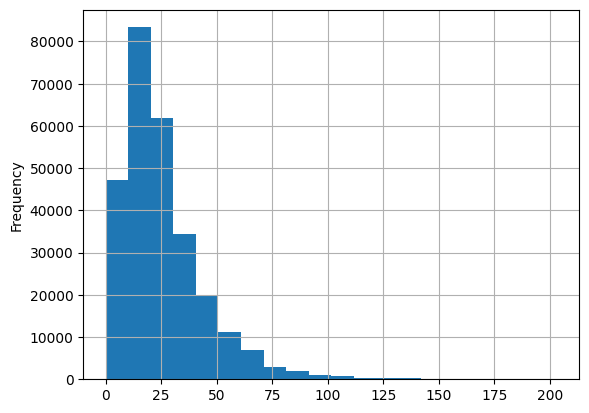

In [ ]:
# Create a histogram of the inspection_score variable
df_subset['inspection_score'].plot.hist(bins = 20, grid = True)

# Looks like the inspection_score distribution is skewed right
# There could be possible outlier(s) around 125-200 score

<Axes: >

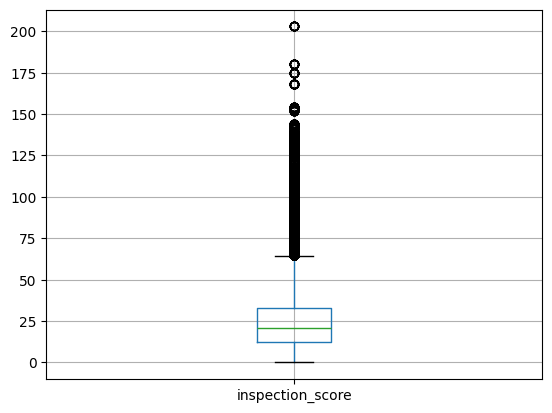

In [ ]:
# Inspect outliers further through boxplot
# Create a boxplot to determine the specific location of the outlier(s)
df_subset.boxplot(column = 'inspection_score')

In [ ]:
# Statistical description
print('Statistical description for inspection_score:\n', df_subset['inspection_score'].describe())

Statistical description for inspection_score:
 count    272116.000000
mean         25.327379
std          18.813369
min           0.000000
25%          12.000000
50%          21.000000
75%          33.000000
max         203.000000
Name: inspection_score, dtype: float64


Analysis: There are outliers in the inspection_score distribution; however, we do not think that we should remove these observations. Upon further research, the scores are the sum of violation points during inspections (the lower the score the better). In NYC, the inspection score can be greater than 100 (these are valid observations). Although they are outliers, these could be valuable to understand the restaurant landscape.

**Investigate multiple variables' distributions and trends at once**

In [ ]:
# Create a MinMaxScaler function
def MinMaxScaler(x):
  # Pre-compute the max and min of the variable
  max_x = np.max(x)
  min_x = np.min(x)

  # Calculate and return the newly scaled version of the variable
  u = (x - min_x) / (max_x - min_x)
  return u

In [ ]:
# Normalize longitude to ensure that it does not disproportionately dominate analysis (many values)
longitude_scaled = MinMaxScaler(df_subset['longitude'])

# Normalize latitude to ensure that it does not disproportionately dominate analysis (many values)
latitude_scaled = MinMaxScaler(df_subset['latitude'])

Length of longitude: 272116
Length of latitude: 272116


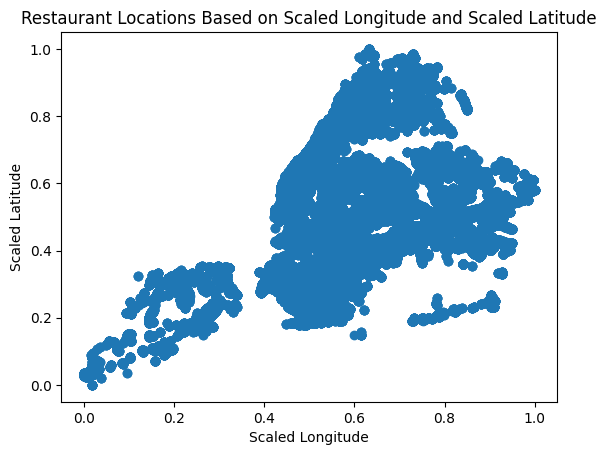

In [ ]:
# Inspect the latitude and longtitude variables

# Make sure that latitude and longtitude are the same length
print('Length of longitude:', len(df_subset['longitude']))
print('Length of latitude:', len(df_subset['latitude']))

plt.scatter(longitude_scaled, latitude_scaled)
plt.xlabel('Scaled Longitude')
plt.ylabel('Scaled Latitude')
plt.title('Restaurant Locations Based on Scaled Longitude and Scaled Latitude')
plt.show()

In [ ]:
# Statistical description
print('Statistical description for latitude:\n', df_subset['latitude'].describe(), '\n')
print('Statistical description for longitude:\n', df_subset['longitude'].describe())

Statistical description for latitude:
 count    272116.000000
mean         40.728327
std           0.067973
min          40.499563
25%          40.688685
50%          40.733491
75%          40.761575
max          40.912822
Name: latitude, dtype: float64 

Statistical description for longitude:
 count    272116.000000
mean        -73.940138
std           0.076218
min         -74.248708
25%         -73.988770
50%         -73.956326
75%         -73.896648
max         -73.700928
Name: longitude, dtype: float64


Analysis: There does not seem to be any outliers. Another interesting thing that this scatterplot tells us is that there seem to be two distinct groups of restaurants. One group is from longitude -74.2 to -74.1 and latitude 40.5 to 40.6. The other group is from longitude -74.0 to 73.7 and latitude from 40.55 to 40.9.

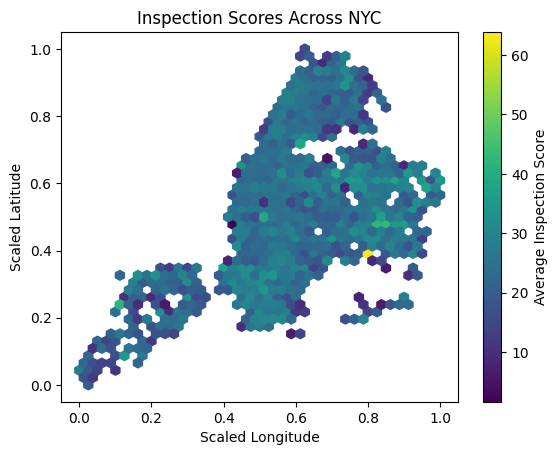

In [ ]:
# Look at inspection score relation with longitude and latitude
plt.hexbin(
    longitude_scaled, latitude_scaled,
    C= df_subset["inspection_score"],
    gridsize=40,
    reduce_C_function= np.mean)

plt.colorbar(label = "Average Inspection Score")
plt.xlabel('Scaled Longitude')
plt.ylabel('Scaled Latitude')
plt.title('Inspection Scores Across NYC')
plt.show()

Analysis: The graph represents the geographical areas of New York City based on the longitudinal and latitude values. plt.hexbin() takes the longitude and latitude values and plots them on the graphs identifying locations of restaurants. The graph utilizes a gradient that indicates the average inspection score, where the darker the color, the less violations the restaurant has earned. Based on this, it seems there is specific location around -73.8 (longitude) and 40.65 (latitude) that received an average score of 60. This restaurant seems to be located in Queens.

However, this hexbin plot is not very informative for what we are trying to investigate. Because we compared both longtiude and latitude, this plot tells us about the groupings but it does not tell us the relationship between longitude and latitude in terms of an inspection score relationship. It shows us more where the restaurants are spatially in NYC and how the inspection scores vary.

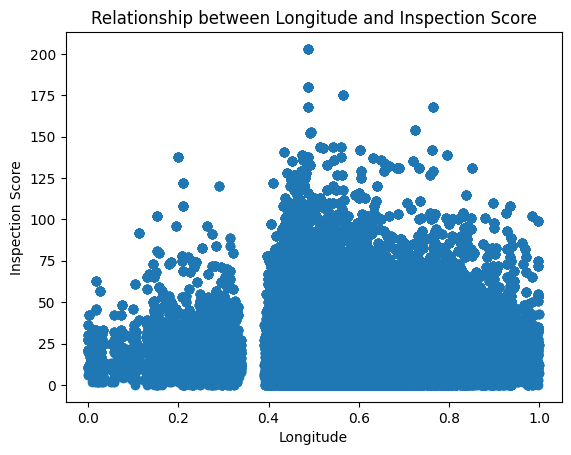

In [ ]:
# Investigate relationship between inspection score and longitude

# Create a scatter plot
plt.scatter(longitude_scaled, df_subset['inspection_score'])
plt.xlabel('Longitude')
plt.ylabel('Inspection Score')
plt.title('Relationship between Longitude and Inspection Score')
plt.show()

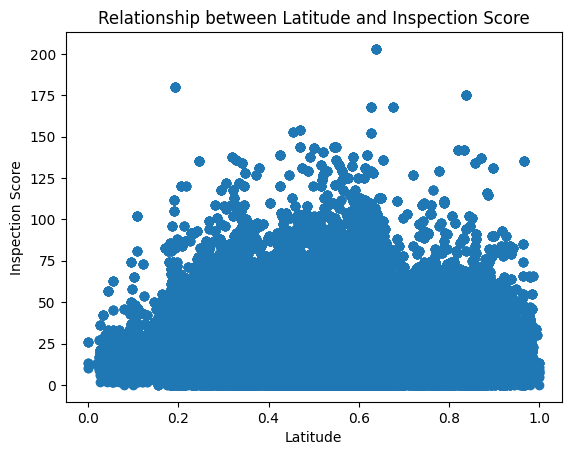

In [ ]:
# Investigate relationship between inspection score and latitude

# Create a scatter plot
plt.scatter(latitude_scaled, df_subset['inspection_score'])
plt.xlabel('Latitude')
plt.ylabel('Inspection Score')
plt.title('Relationship between Latitude and Inspection Score')
plt.show()

There does not seem to be a relationship between the (scaled) longitude and latitude. While we originally believed there was a relationship between the inspection score and the geographical location, the scatterplots above reveal that there are no strong relationships as there are no noticeable trends between the data. Longitude and latitude may be too granular for our interests, so we may want to look at the relationship between inspection scores and boroughs.

**Investigate categorical variables (both the target and explanatory variables)**

In [ ]:
# Look at what columns are categorical
df_subset_categorical = df_subset.select_dtypes(include=['object', 'category', 'bool']).columns

print('Categorical Variables:\n', df_subset_categorical)

Categorical Variables:
 Index(['zipcode', 'inspection_type', 'bbl', 'bronx', 'brooklyn', 'manhattan',
       'queens', 'staten_island', 'afghan', 'african', 'american', 'armenian',
       'asian/asian_fusion', 'australian', 'bagels/pretzels',
       'bakery_products/desserts', 'bangladeshi', 'barbecue', 'basque',
       'bottled_beverages', 'brazilian', 'cajun', 'californian', 'caribbean',
       'chicken', 'chilean', 'chimichurri', 'chinese', 'chinese/cuban',
       'chinese/japanese', 'coffee/tea', 'continental', 'creole',
       'creole/cajun', 'czech', 'donuts', 'eastern_european', 'egyptian',
       'english', 'ethiopian', 'filipino', 'french', 'frozen_desserts',
       'fruits/vegetables', 'fusion', 'german', 'greek', 'hamburgers',
       'haute_cuisine', 'hawaiian', 'hotdogs', 'hotdogs/pretzels', 'indian',
       'indonesian', 'iranian', 'irish', 'italian', 'japanese',
       'jewish/kosher', 'juice,_smoothies,_fruit_salads', 'korean',
       'latin_american', 'lebanese', 'medit

The target variable, inspection score, is a floating-point number and therefore a continuous numeric variable rather than a categorical variable. Therefore, we will focus the investigation on the categorical explanatory variables.

In [ ]:
df['inspection_score'].dtype

dtype('float64')

In [ ]:
# Investigate categorical explanatory variables

# Look at zipcode
print('First 10 Value Counts of Zipcode:\n', df_subset['zipcode'].value_counts().head(10), '\n')

# Look at inspection type
print('Value Counts of Inspection Type:\n', df_subset['inspection_type'].value_counts(normalize=True), '\n')

# Look at the boroughs
print('Mean of the Boroughs:\n', df_subset[['bronx','brooklyn','manhattan','queens','staten_island']].mean(), '\n')

First 10 Value Counts of Zipcode:
 zipcode
10003    6141
10019    5790
10013    5764
11354    5762
10001    5603
10002    5465
10036    5068
11372    4740
10016    4618
11201    4330
Name: count, dtype: int64 

Value Counts of Inspection Type:
 inspection_type
Cycle Inspection / Initial Inspection                          0.556843
Cycle Inspection / Re-inspection                               0.213266
Pre-permit (Operational) / Initial Inspection                  0.146901
Pre-permit (Operational) / Re-inspection                       0.038730
Pre-permit (Non-operational) / Initial Inspection              0.013355
Cycle Inspection / Reopening Inspection                        0.009643
Pre-permit (Operational) / Compliance Inspection               0.007361
Cycle Inspection / Compliance Inspection                       0.004781
Inter-Agency Task Force / Initial Inspection                   0.003039
Pre-permit (Operational) / Reopening Inspection                0.002925
Pre-permit (Non-ope

Analysis: The categorical explanatory variables have varying degrees of class imbalance. Zipcode is very skewed as small number of zipcodes account for large amounts of the observations. Inspection type seems pretty imbalanced as many of the observations are a part of the Cycle Inspection / Initial Inspection group (55.68%). Borough distributions are also imbalanced as many of the observations are a part of the Manhattan group (36.6%) compared to the Bronx and Staten Island.

**Create group visualizations of numeric distributions grouped by a categorical variable**

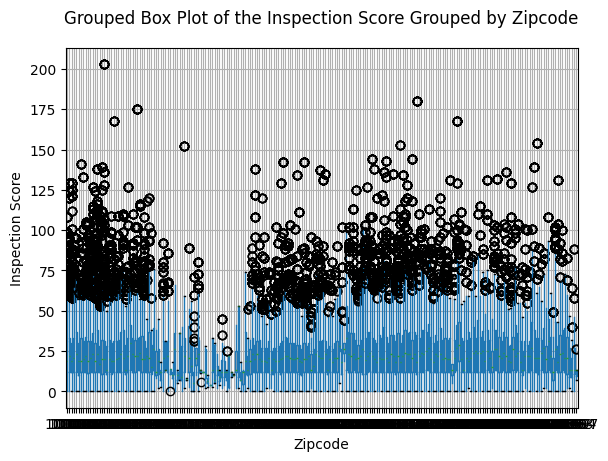

In [ ]:
# Create a grouped box plot of the inspection_score grouped by the zipcode

df_subset.boxplot(column = 'inspection_score', by = 'zipcode')

# Override default title
plt.title('')
plt.suptitle('Grouped Box Plot of the Inspection Score Grouped by Zipcode')

plt.xlabel('Zipcode')
plt.ylabel('Inspection Score')
plt.show()

In [ ]:
df_subset['zipcode'].count()

np.int64(272116)

**Describe how the distribution changes for each group in that categorical variable. Could these trends be informative in a model?**

The group boxplot of inspection_score grouped by the zipcode is very dense and not informative. While the zipcode is a categorical variable, it should not be displayed in this manner because each individual zipcode is a different observation. There are 272116 total zipcode observations in our dataset. The plethora of observations distort the viewer's understanding of the relation between the inspection score and the zipcode, making it unreadable. As a suggestion, we should, instead, look at the boroughs because they better distinguish between the regions we are interested in while maintaining plot readability.

In [ ]:
# Statistical description

stats_by_zipcode = df_subset.groupby('zipcode')['inspection_score'].describe()
print('Statistical description for zipcode:\n', stats_by_zipcode)

Statistical description for zipcode:
           count       mean        std  min    25%   50%   75%    max
zipcode                                                             
10001    5603.0  23.136891  16.894004  0.0  12.00  19.0  31.0  108.0
10002    5465.0  25.980055  19.569576  0.0  12.00  22.0  33.0  129.0
10003    6141.0  23.356619  18.112996  0.0  12.00  19.0  30.0  129.0
10004    1316.0  24.341185  18.405071  0.0  11.75  21.0  33.0   96.0
10005     645.0  25.801550  19.170395  0.0  12.00  23.0  37.0   95.0
...         ...        ...        ...  ...    ...   ...   ...    ...
11691     432.0  25.391204  17.785581  2.0  11.00  21.0  34.0   83.0
11692      91.0  18.505495  11.740125  2.0   9.00  13.0  27.0   47.0
11693     223.0  16.452915  11.920770  0.0   9.00  13.0  21.0   64.0
11694     284.0  20.566901  16.327883  0.0  10.75  13.0  27.0   88.0
11697      14.0  14.357143   6.605442  7.0   9.75  13.0  13.0   26.0

[218 rows x 8 columns]


**Describe how these statistics change for each group within a categorical variable. Could these differences be informative in a model?**

The count variable shows that there are a differing amount of restaurants in each zipcode. The standard deviation suggests that there is a variation between the inspection scores based on location (zipcode). Additionally, all of the quartile values differ by the relation between the zipcode and the inspection score ultimately suggesting that zipcode may be an important factor in the inspection score for restaurants.

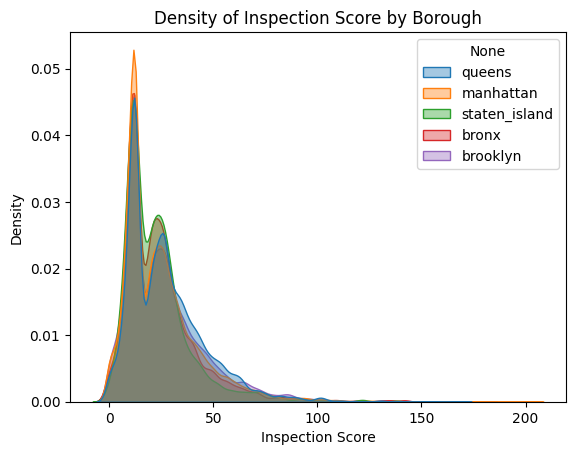

In [ ]:
import seaborn as sns # Import Seaborn

borough_columns = ['bronx', 'brooklyn', 'manhattan', 'queens', 'staten_island']

# Determine which borough each row belongs to at plotting time, so you do not have to add a new column to df
borough_for_plot = df_subset[borough_columns].idxmax(axis=1)

# Create a grouped density plot (KDE plot) of the inspection_score grouped by the boroughs
sns.kdeplot(
    x=df_subset['inspection_score'],
    hue=borough_for_plot,
    fill=True,
    common_norm=False, # Normalize each borough independently
    alpha=0.4
)

plt.title("Density of Inspection Score by Borough")
plt.xlabel("Inspection Score")
plt.ylabel("Density")
plt.show()

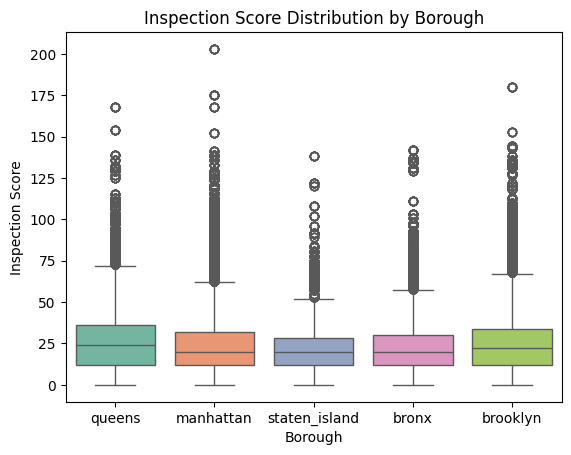

In [ ]:
import seaborn as sns # Import Seaborn

# Inspect the outliers more through a boxplot
# Create a side-by-side box plot of the inspection_score grouped by the boroughs
sns.boxplot(
    x=borough_for_plot,
    y=df_subset['inspection_score'],
    hue=borough_for_plot,
    palette='Set2',
    legend=False
)

plt.title("Inspection Score Distribution by Borough")
plt.xlabel("Borough")
plt.ylabel("Inspection Score")
plt.show()

**Describe how the distribution changes for each group in that categorical variable. Could these trends be informative in a model?**

As shown through the group box plot, the median for all of the boroughs are relatively the same. Additionally, the 1st and 3rd quartile are similar. However, the outliers differ between the boroughs. For instance, Manhattan has one of the highest inspection scores at around 200 in comparison to Staten Island's outlier reaching about a score of 150. As shown through the grouped KDE plot, the density peak of the Manhattan borough is noticeably higher than the other boroughs. At this peak, Manhattan has density > 0.05. In the future, we should investigate more into the potential cause for the disparities of Manhattan inspection scores.

These trends could be informative to the model because it shows a differentiation between the borough location and the inspection scores.

In [ ]:
# Statistical description
stats_by_borough = df_subset.groupby(borough_for_plot)['inspection_score'].describe()
print('Statistical description for NYC boroughs:\n', stats_by_borough)

Statistical description for NYC boroughs:
                  count       mean        std  min   25%   50%   75%    max
bronx          25233.0  23.754409  17.425506  0.0  12.0  20.0  30.0  142.0
brooklyn       70486.0  25.801095  19.630012  0.0  12.0  22.0  34.0  180.0
manhattan      99602.0  24.503072  18.642544  0.0  12.0  20.0  32.0  203.0
queens         67495.0  26.978102  18.830804  0.0  12.0  24.0  36.0  168.0
staten_island   9300.0  22.852903  16.576319  0.0  12.0  20.0  28.0  138.0


**Describe how these statistics change for each group within a categorical variable. Could these differences be informative in a model?**

The statistical description shows that the counts are different, but we normalized them by each borough to ensure that the population is not a confounding factor in the analysis. Therefore, the differences in the count should not be an issue. The mean, standard deviation, and all of the quartiles are similar to each other; however, the max value varies widely. This supports our idea that there is variation between the restaurant location and the inspection scores. Furthermore, Manhattan has a noticeably higher max value of 203.0 relative to the other borough's max inspections scores.

In [ ]:
# Look at the unique values of inspection_type
print('Unique Values of inspection_type:\n', df_subset['inspection_type'].unique(), '\n')

# Look at how many rows are in each inspection type
print('Value counts of inspection_type:\n', df_subset['inspection_type'].value_counts())

Unique Values of inspection_type:
 ['Cycle Inspection / Re-inspection'
 'Cycle Inspection / Initial Inspection'
 'Pre-permit (Operational) / Re-inspection'
 'Inter-Agency Task Force / Initial Inspection'
 'Pre-permit (Operational) / Initial Inspection'
 'Pre-permit (Operational) / Compliance Inspection'
 'Cycle Inspection / Reopening Inspection'
 'Pre-permit (Non-operational) / Initial Inspection'
 'Cycle Inspection / Compliance Inspection'
 'Pre-permit (Operational) / Second Compliance Inspection'
 'Pre-permit (Operational) / Reopening Inspection'
 'Cycle Inspection / Second Compliance Inspection'
 'Pre-permit (Non-operational) / Re-inspection'
 'Pre-permit (Non-operational) / Compliance Inspection'
 'Pre-permit (Non-operational) / Second Compliance Inspection'
 'Inter-Agency Task Force / Re-inspection'] 

Value counts of inspection_type:
 inspection_type
Cycle Inspection / Initial Inspection                          151526
Cycle Inspection / Re-inspection                             

In [ ]:
# Look at how many different scores each inspection type has
df_subset.groupby('inspection_type')['inspection_score'].nunique()

,inspection_score
inspection_type,
Cycle Inspection / Compliance Inspection,69
Cycle Inspection / Initial Inspection,122
Cycle Inspection / Re-inspection,106
Cycle Inspection / Reopening Inspection,63
Cycle Inspection / Second Compliance Inspection,15
Inter-Agency Task Force / Initial Inspection,13
Inter-Agency Task Force / Re-inspection,1
Pre-permit (Non-operational) / Compliance Inspection,14
Pre-permit (Non-operational) / Initial Inspection,111


inspection_type group "Inter-Agency Task Force / Re-inspection" has no variation in inspection_score. When making a group density plot, this can cause issues. Therefore, plot a boxplot of the inspection_score grouped by the inspection_type because it plots even if a group has little or no variation.

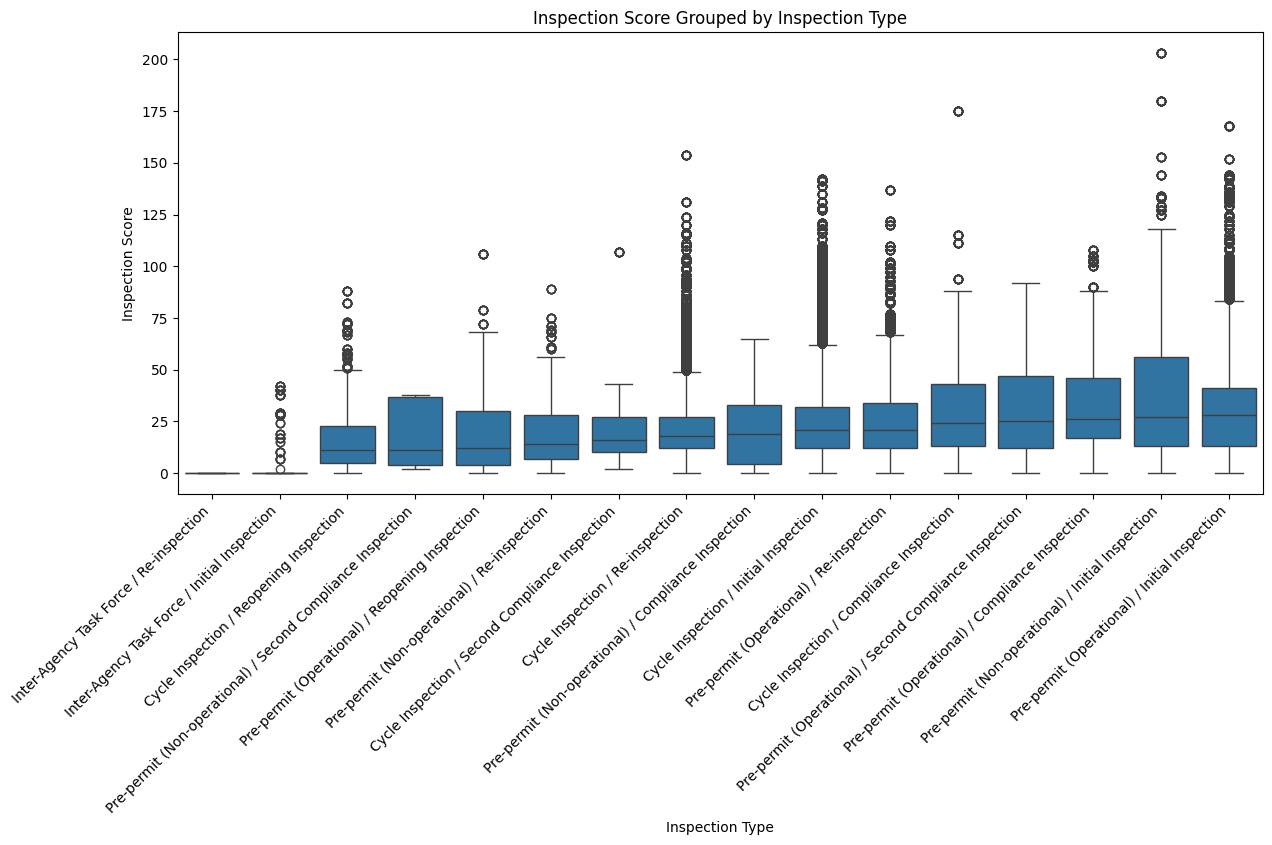

In [ ]:
# Create a boxplot of the inspection_score grouped by the inspection_type

plt.figure(figsize=(14, 6)) # Extend the boxplot size

# Order from low to high median values
order = (df_subset.groupby('inspection_type')['inspection_score'].median().sort_values().index)

sns.boxplot(
    data=df_subset,
    x='inspection_type',
    y='inspection_score',
    order=order
)

plt.title("Inspection Score Grouped by Inspection Type")
plt.xlabel("Inspection Type")
plt.ylabel("Inspection Score")
plt.xticks(rotation=45, ha='right') # Angle the inspection_type for readability

plt.show()

**Describe how the distribution changes for each group in that categorical variable. Could these trends be informative in a model?**

One way that the distribution changes for each group in inspection type is in the median inspection scores. Some inspection types, such as initial inspections, compliance inspection, and second compliance tend to have higher median scores (approximately 20–30). Other inspection types, such as reopening inspection and re-inspection, tend to have lower medians (approximately 10–20). This suggests that follow-up inspections often result in lower scores, possibly because prior issues have already been addressed.

Another difference is the spread of the distributions. For instance, inspection types like cycle inspection/compliance and second compliance tend to have wider IQRs and longer whiskers, indicating high variability in scores. In contrast, other inspection types like inter-agency task force and re-inspection tend to have tighter spreads, suggesting more consistent outcomes.

Additionally, the amount of outliers varies across groups. Some inspection types, such as cycle inspection/re-inspection and pre-permit (non-operational)/initial inspection, contain many extreme outliers (approximately 150-200 range), suggesting the occassional severe violations. Others, like pre-permit (non-operational)/compliance inspection and pre-permit (operational)/second compliance, have few to no outliers, suggesting more stable inspection outcomes.

These trends are informative for a model because the inspection type reveals important contextual information about the reasons for the inspection. For instance, whether it was the restaurant's first inspection or a follow-up inspection, and the compliance seems to influence the score and its variability. This suggests that the inspection type is a strong predictor of inspection scores and should be included as a feature in a predictive model.

In [ ]:
# Statistical description
stats_by_inspection_type = df_subset.groupby('inspection_type')['inspection_score'].describe()
print('Statistical description for inspection type:\n', stats_by_inspection_type)

Statistical description for inspection type:
                                                        count       mean  \
inspection_type                                                           
Cycle Inspection / Compliance Inspection              1301.0  32.633359   
Cycle Inspection / Initial Inspection               151526.0  24.503122   
Cycle Inspection / Re-inspection                     58033.0  22.746024   
Cycle Inspection / Reopening Inspection               2624.0  16.537729   
Cycle Inspection / Second Compliance Inspection         81.0  28.358025   
Inter-Agency Task Force / Initial Inspection           827.0   2.055623   
Inter-Agency Task Force / Re-inspection                  1.0   0.000000   
Pre-permit (Non-operational) / Compliance Inspe...      62.0  21.258065   
Pre-permit (Non-operational) / Initial Inspection     3634.0  38.161530   
Pre-permit (Non-operational) / Re-inspection           482.0  20.825726   
Pre-permit (Non-operational) / Second Complianc...    

**Describe how these statistics change for each group within a categorical variable. Could these differences be informative in a model?**

For almost all of the inspection types, the mean is greater than the median, suggesting that the data set is right-skewed. For example, for the Pre-permit (Non-operational) / Initial Inspection, the mean is 38.16 and the median is 27. This indicates a long right tail which is supported by the maximum inspection score value of 203. Some of the mean-median differences are not as high. For instance, Inter-Agency Task Force / Initial Inspection has a mean of 2.06 and a median of 0, with a maximum value of 42. This may be because this inspection type is a lower-intensity inspection type.

Furthermore, the spread (standard deviation) differs a lot between the inspection type groups. Some groups have very high variability, such as Pre-permit (Non-operational) / Initial Inspection with a standard deviation of 33.54 and Cycle Inspection / Compliance Inspection with a standard deviation of 28.73. Other groups have moderate variability like Cycle Inspection / Re-inspection with a standard deviation of 16.62. Other groups have a low variability like iInter-Agency Task Force / Initial Inspection with standard deviation of 7.82.

These differences are informative for a model. The median vastly differs as well, from 0 to 38.0, showing the range of the values. As well as the quartiles, the minimum and maximum vary between the inspection types. Most of the inspection types start at 0, but their maximum differs, ranging from 38 to 175, Pre-permit (Non-operational) / Second Compliance and Cycle Inspection / Compliance Inspection, respectively. While many values are similar within the range, these outstanding outliers emphasize the differences between each group within the categorical variable, suggesting that there may be many other factors influencing the inspection types.

**Look at the trends between all of your numeric predictor variables and the outcome variable. Which attributes seem to be the most correlated with the outcome variable? Support your answer with a correlation matrix or visualization.**

The numeric predictor variable we looked at was inspection_score. The numeric outcome variables we looked at were latitude and longitude. Originally, we thought latitude and longtitude by themselves were not very informative, so we combined these values together to create coordinate points. Therefore, we had only one numeric predictor variable and "one" numeric outcome variable. For a correlation matrix, however, we should not combine them into one variable (coordinate pair) because this would produce a non-numeric value and would lose interpretability in a correlation analysis. Additionally, combining them into coordinate pairs would allow the viewer to plot the coordinates of NYC, but this is not informative for our project goals.

In [ ]:
# Calculate the correlation matrices of latitude, longitude, and inspection_score
# Define the variables to consider
vars = ['latitude', 'longitude', 'inspection_score']

# Compute the covariance and correlations of the variables
cor = df.loc[:, vars].corr()

print("Correlation Matrix:\n", cor, '\n')

Correlation Matrix:
                   latitude  longitude  inspection_score
latitude          1.000000   0.367902         -0.014460
longitude         0.367902   1.000000          0.045356
inspection_score -0.014460   0.045356          1.000000 



Analysis: While the correlation between the latitude and longitude vs. inspection score is relatively weak. It is important to acknowledge that correlation only measures linear relationships. Therefore, we should not wholly discount a possibility of a relationship because it could be a higher order relationship.

**Consider the trends between multiple numeric variables with one another. Are any variables strongly correlated with one another? What issues could this introduce into a model? Support your answer with a correlation matrix or visualization.**

The numeric variables in the dataframe include restaurant_id, inspection_score, latitude, longitude, community_board, and council_district. We found that inspection_score, latitude, and longitude were the most informative for what we want to inspect. These values have a weak linear relationship as shown by the correlation matrix; therefore, this should not interfere with our model. In addition, there was a 'location' column which had the same information as the latitude and longitude (as a coordinate pair), but it was removed because of redundancy which could have caused collinearity.

### EDA Summary:

**From your EDA, compile your most important findings in a short paragraph. For each of your takeaways, point to specific tables or visualizations you generated that support your interpretations. Consider what this means for your final model.**

Manhattan is an important borough to explore further because of the outliers in the inspection score data. Even though the relationship between the numeric predictor and outcome variables are non-linear, this does not mean there is no relationship at all. The correlation is just measuring a linear relationship. We could explore other relationships such as inspection scores and boroughs. Additionally, there is an importance of normalizing data, most notably the borough data, because you do not want the count to effect the interpretation of the data (some boroughs may have more restaurants depending on the population density, popularity, etc).

For the final model, we should explore why Manhattan is significantly different than the others. Additionally, we could explore which Manhattan restaurant(s) have really high inspection score ratings (203) and the possible reasons as to why.

## Appropriate Models (SL):
*   Is your research problem regression or classification?
*   Is your research problem supervised or unsupervised learning?
*   Given these attributes of your project, what potential models that
we’ve discussed could you use?
*   Given the attributes of the features in your data set, which of these
possible models make the most sense for your data?
*   What feature engineering decisions do you want to include in your
model if applicable? Examples include data transformations, interac-
tion terms, polynomial expansions, and other basis expansions. Point
to specific trends you found in the EDA section of this project check-
point that inform this desire. Create these features.
*   Do you have concerns about overfitting or underfitting your model
given your model choice?







**Is your research problem regression or classification? Is your research problem supervised or unsupervised learning?** (Haley)

As we are trying to predict the numeric score from the inspector, we would classify this as a regression problem. Also, we are planning to train and test this model on previous scores that we found, so this would be a supervised learning problem.



**What potential models that we’ve discussed could you use? which of these possible models make the most sense for your data?** (Haley)

From the models we have looked at in class, we would be able to use KNN Regression, Simple Linear Regression, or Multiple Linear Regression. As Linear Regression is able to handle models that have a larger set of explanatory vairables by generating a prediction as an aggregation of the input variables, that will, most likely, be the model that works best.



**What feature engineering decisions do you want to include in your model if applicable?** (Haley)

1st Feature engineering: Create Month and Day features from Ins
pection Date, and remove the Inspection Date feature. Do not create a Year feature from it though.

We want to remove the year from Inspection Date, so we can extrapolate. If we keep the year, then model cannot be used to predict any inspection results beyond 2026, because for example, if the year is 2027, it will see that the data it learned from does not have 2027 in it, so it will not be able to predict.

In [ ]:
#removing the year
saved_df['INSPECTION DATE'] = saved_df['INSPECTION DATE'].dt.strftime('%m-%d')
saved_df.head()

,CAMIS,BORO,ZIPCODE,CUISINE DESCRIPTION,INSPECTION DATE,ACTION,VIOLATION CODE,VIOLATION DESCRIPTION,CRITICAL FLAG,SCORE,INSPECTION TYPE,Latitude,Longitude,Community Board,Council District,BBL
11,50107021,Queens,11103,Chinese,02-27,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Re-inspection,40.761143,-73.909163,401.0,22.0,4007290046.0
14,50070952,Queens,11373,Pizza,02-02,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,4.0,Cycle Inspection / Re-inspection,40.742031,-73.874286,404.0,25.0,4015860040.0
92,41185899,Manhattan,10001,Korean,05-29,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Initial Inspection,40.747443,-73.986170,105.0,4.0,1008340049.0
110,41659970,Manhattan,10013,Chinese,03-15,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,12.0,Cycle Inspection / Re-inspection,40.717210,-74.000602,101.0,1.0,1001977502.0
126,50129451,Staten Island,10312,Pizza,12-22,Violations were cited in the following area(s).,02B,Hot TCS food item not held at or above 140 °F.,Critical,10.0,Pre-permit (Operational) / Re-inspection,40.559438,-74.169534,503.0,51.0,5055330047.0


2nd feature engineering: We wanted to combine some of the columns that were previously made. By one-hot encoding the BORO and CUISINE TYPE, we gained 80+ columns. To remediate this, we bunched the CUISINE TYPE by country, leaving a few that we thought belonged in a different category. We removed a few that either did not have a lot of observations or we thought wouldn't help with predicting/fit in a bucket.

In [ ]:
cuisine_map = {

# American / North American
'American': 'American',
'New American': 'American',
'Californian': 'American',
'Soul Food': 'American',
'Southwestern': 'American',

# Latin American / Caribbean
'Latin American': 'Latin American',
'Caribbean': 'Latin American',
'Mexican': 'Latin American',
'Tex-Mex': 'Latin American',
'Peruvian': 'Latin American',
'Brazilian': 'Latin American',
'Chilean': 'Latin American',
'Chimichurri': 'Latin American',

# European
'French': 'European',
'Haute Cuisine': 'French', #french cuisine
'New French': 'European',
'Italian': 'European',
'Spanish': 'European',
'Portuguese': 'European',
'German': 'European',
'Greek': 'European',
'Irish': 'European',
'English': 'European',
'Polish': 'European',
'Russian': 'European',
'Czech': 'European',
'Scandinavian': 'European',
'Eastern European': 'European',
'Basque': 'European',
'Continental': 'European',

# Asian
'Chinese': 'Asian',
'Chinese/Japanese': 'Asian',
'Chinese/Cuban': 'Asian',
'Japanese': 'Asian',
'Korean': 'Asian',
'Thai': 'Asian',
'Indian': 'Asian',
'Pakistani': 'Asian',
'Bangladeshi': 'Asian',
'Indonesian': 'Asian',
'Filipino': 'Asian',
'Southeast Asian': 'Asian',
'Asian/Asian Fusion': 'Asian',

# Middle Eastern / Mediterranean / African
'Mediterranean': 'Middle Eastern/African',
'Middle Eastern': 'Middle Eastern/African',
'Lebanese': 'Middle Eastern/African',
'Turkish': 'Middle Eastern/African',
'Iranian': 'Middle Eastern/African',
'Egyptian': 'Middle Eastern/African',
'Moroccan': 'Middle Eastern/African',
'Afghan': 'Middle Eastern/African',
'Armenian': 'Middle Eastern/African',
'African': 'Middle Eastern/African',
'Ethiopian': 'Middle Eastern/African',
'Jewish/Kosher': 'Middle Eastern/African',

# Breakfast
'Bakery Products/Desserts': 'Breakfast',
'Bagels/Pretzels': 'Breakfast',
'Pancakes/Waffles': 'Breakfast',
'Nuts/Confectionary': 'Breakfast',
'Donuts': 'Breakfast',

 #Drink
'Coffee/Tea': 'Drink',
'Juice, Smoothies, Fruit Salads': 'Drink',
 'Bottled Beverages': 'Drink',

 #Oceania - felt weird grouping this with america
'Hawaiian': 'Oceania',
'Polynesian': 'Oceania',

 #soups, salads, sandwiches
'Sandwiches': 'Soups/Salads/Sandwiches',
'Salads': 'Soups/Salads/Sandwiches',
'Soups': 'Soups/Salads/Sandwiches',
 'Soups/Salads/Sandwiches': 'Soups/Salads/Sandwiches',
'Sandwiches/Salads/Mixed Buffet': 'Sandwiches/Salads/Mixed Buffet',

#other foods I thought should be on their own - perhaps things from america should be added
'Seafood': 'Seafood',
 'Pizza': 'Pizza',
'Fusion': 'Fusion',

 #dietary restrictions
 'Vegan': 'Vegan',
'Vegetarian': 'Vegitarian',

 #Meat
'Steakhouse': 'Meat',
'Hamburgers': 'Meat',
'Hotdogs': 'Meat',
'Hotdogs/Pretzels': 'Meat',
'Barbecue': 'Meat',
'Chicken': 'Meat',

 #TO DELETE - specific or non specific things I dont know how to group
 #do i drop the rows with these in it or just the column ???
 'Frozen Desserts': 'TODELETE',
'Tapas': 'TODELETE',
'Fruits/Vegetables': 'TODELETE',
'Other': 'TODELETE',
'Not Listed/Not Applicable': 'TODELETE'
}

saved_df['CUISINE_GROUP'] = saved_df['CUISINE DESCRIPTION'].map(cuisine_map)
saved_df.head()

,CAMIS,BORO,ZIPCODE,CUISINE DESCRIPTION,INSPECTION DATE,ACTION,VIOLATION CODE,VIOLATION DESCRIPTION,CRITICAL FLAG,SCORE,INSPECTION TYPE,Latitude,Longitude,Community Board,Council District,BBL,CUISINE_GROUP
11,50107021,Queens,11103,Chinese,02-27,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Re-inspection,40.761143,-73.909163,401.0,22.0,4007290046.0,Asian
14,50070952,Queens,11373,Pizza,02-02,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,4.0,Cycle Inspection / Re-inspection,40.742031,-73.874286,404.0,25.0,4015860040.0,Pizza
92,41185899,Manhattan,10001,Korean,05-29,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Initial Inspection,40.747443,-73.986170,105.0,4.0,1008340049.0,Asian
110,41659970,Manhattan,10013,Chinese,03-15,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,12.0,Cycle Inspection / Re-inspection,40.717210,-74.000602,101.0,1.0,1001977502.0,Asian
126,50129451,Staten Island,10312,Pizza,12-22,Violations were cited in the following area(s).,02B,Hot TCS food item not held at or above 140 °F.,Critical,10.0,Pre-permit (Operational) / Re-inspection,40.559438,-74.169534,503.0,51.0,5055330047.0,Pizza


In [ ]:
#copied code to complete this

categorical_vars_to_encode = ['BORO', 'CUISINE_GROUP']
for i, var in enumerate(categorical_vars_to_encode):

  # Create the dummies
  if i == 0:
    one_hot_encoding_mat = pd.get_dummies(saved_df[var])
  else:
    added_columns = pd.get_dummies(saved_df[var])
    one_hot_encoding_mat = pd.concat([one_hot_encoding_mat, added_columns], axis = 1)

one_hot_encoding_mat.head()

saved_df = pd.concat([saved_df.drop(columns=categorical_vars_to_encode), one_hot_encoding_mat], axis=1)
saved_df = saved_df.drop('TODELETE', axis = 1)

df = saved_df.rename(columns={
    'CAMIS': 'restaurant_id',
    'BORO': 'borough_name',
    'ZIPCODE': 'zipcode',
    'CUISINE DESCRIPTION': 'cuisine_type',
    'INSPECTION DATE': 'inspection_date',
    'SCORE': 'inspection_score',
    'Latitude': 'latitude',
    'Longitude': 'longitude',
    'Community Board': 'community_board',
    'Council District': 'council_district'
})

# Convert column names to lowercase
df.columns = df.columns.str.lower()

# Replace spaces with underscores
df.columns = df.columns.str.replace(" ", "_")

# Replace hyphens with underscores
df.columns = df.columns.str.replace("-", "_")

df.head()

,restaurant_id,zipcode,cuisine_type,inspection_date,action,violation_code,violation_description,critical_flag,inspection_score,inspection_type,...,latin_american,meat,middle_eastern/african,oceania,pizza,sandwiches/salads/mixed_buffet,seafood,soups/salads/sandwiches,vegan,vegitarian
11,50107021,11103,Chinese,02-27,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Re-inspection,...,False,False,False,False,False,False,False,False,False,False
14,50070952,11373,Pizza,02-02,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,4.0,Cycle Inspection / Re-inspection,...,False,False,False,False,True,False,False,False,False,False
92,41185899,10001,Korean,05-29,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Initial Inspection,...,False,False,False,False,False,False,False,False,False,False
110,41659970,10013,Chinese,03-15,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,12.0,Cycle Inspection / Re-inspection,...,False,False,False,False,False,False,False,False,False,False
126,50129451,10312,Pizza,12-22,Violations were cited in the following area(s).,02B,Hot TCS food item not held at or above 140 °F.,Critical,10.0,Pre-permit (Operational) / Re-inspection,...,False,False,False,False,True,False,False,False,False,False


3rd feature engineering idea:BBL feature (borough block lot) can be split up into 3 features. The 1st digit is borough, next five digits are block, and the last four are lot. It's a standardized format so we could just index into the value and get these features.

In [ ]:
df['borough_id'] = df['bbl'].astype(str).str[0]
df['block_id'] = np.where(
    df['bbl'].astype(str).str.len() == 12,
    df['bbl'].astype(str).str[1:6],
    np.nan
)

df['lot_id'] = np.where(
    df['bbl'].astype(str).str.len() == 12,
    df['bbl'].astype(str).str[6:10],
    np.nan
)
df.head()

,restaurant_id,zipcode,cuisine_type,inspection_date,action,violation_code,violation_description,critical_flag,inspection_score,inspection_type,...,oceania,pizza,sandwiches/salads/mixed_buffet,seafood,soups/salads/sandwiches,vegan,vegitarian,borough_id,block_id,lot_id
11,50107021,11103,Chinese,02-27,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Re-inspection,...,False,False,False,False,False,False,False,4,00729,0046
14,50070952,11373,Pizza,02-02,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,4.0,Cycle Inspection / Re-inspection,...,False,True,False,False,False,False,False,4,01586,0040
92,41185899,10001,Korean,05-29,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,13.0,Cycle Inspection / Initial Inspection,...,False,False,False,False,False,False,False,1,00834,0049
110,41659970,10013,Chinese,03-15,Violations were cited in the following area(s).,09B,Thawing procedure improper.,Not Critical,12.0,Cycle Inspection / Re-inspection,...,False,False,False,False,False,False,False,1,00197,7502
126,50129451,10312,Pizza,12-22,Violations were cited in the following area(s).,02B,Hot TCS food item not held at or above 140 °F.,Critical,10.0,Pre-permit (Operational) / Re-inspection,...,False,True,False,False,False,False,False,5,05533,0047


4th feature engineering idea: historical features (see the feedback for the project 1 checkpoint for this). these features would be:

Violation code
Violation description
Critical Flag
Inspection Type

We could first run the model with these columns dropped, and then if we need to improve performance, we can create historical features from these. As we have not created the model yet, I will not create this feature, but we may look into it in our next checkpoint.

**Do you have concerns about overfitting or underfitting your model given your model choice?**

We have more concerns of our model being underfitting, because the relationship between food safety outcomes and factors like cuisine type and location may be more complex and nonlinear. This means the model may not fully capture patterns that influence inspection results.

Overfitting is less likely, but it could still occur because several predictors (such as cuisine type or borough) are converted into many dummy variables, increasing the number of parameters in the model. However, since our dataset contains over 296,000 inspection observations, the large sample size helps reduce the risk of severe overfitting.

## Model Using Raw Features (Emma Kee):

**Model choice:** Our outcome variable, inspection score, is a continuous, non-negative variable. Therefore, classification models are not appropriate, as they are designed for predicting discrete categorical outcomes rather than continuous values.

Logistic Regression is also not suitable, as it is a classification model that predicts probabilities of class membership rather than predicting continuous target values.

K-Nearest Neighbors (K-NN) Regression can be used for continuous prediction. However, it was ruled out due to its high computational cost at prediction time. This is especially important given our dataset of around 296,000 observations, which would make the model slow.

Decision Tree models are versatile, as they can handle both classification and regression tasks and are capable of capturing non-linear relationships. However, decision trees are prone to overfitting and typically have high variance if not carefully tuned.

Linear Regression is appropriate for this task because it predicts continuous outcomes, is computationally efficient, and serves as a strong baseline model. Therefore, we selected Linear Regression using only the raw features in the dataset.

In [ ]:
# Import statements
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [ ]:
# Print the numeric features
print('Numeric Features:\n', df.select_dtypes(include=['number']))

Numeric Features:
         restaurant_id  inspection_score   latitude  longitude  \
11           50107021              13.0  40.761143 -73.909163   
14           50070952               4.0  40.742031 -73.874286   
92           41185899              13.0  40.747443 -73.986170   
110          41659970              12.0  40.717210 -74.000602   
126          50129451              10.0  40.559438 -74.169534   
...               ...               ...        ...        ...   
297023       41094080              31.0  40.575460 -73.983020   
297024       50094227               0.0  40.669887 -73.909375   
297025       50105524              12.0  40.708454 -73.831795   
297026       50133623              26.0  40.750360 -73.940293   
297027       50038000              31.0  40.753177 -73.974190   

        community_board  council_district  
11                401.0              22.0  
14                404.0              25.0  
92                105.0               4.0  
110               101.0 

**Numeric feature inclusion decision:** We decided that we were only going to include latitude and longitude columns in the numeric portion of our design matrix. The numeric features in our model include restaurant_id, inspection_score, latitude, longitude, community_board, and council_district. Inspection score is our target variable, so we should not include it in our design matrix. Restaurant id (or originally named CAMIS), for the purposes of predicting the inspection score, is not informative as it is an unique identifier for the restaurant. Furthermore, the community board and council district is not very informative either. We decided to keep both latitude and longitude, as it can inform us about location.

**Side note:** The zipcode column's datatype was changed from a floating point number to a string, which is why it is not specifically included in our numeric feature analysis. Additionally, zipcode is represented by latidue and longitude (location).

In [ ]:
# Categorical features
one_hot_encoding_mat.columns # Represents the one-hot encoded categorical features including just the boroughs and cuisine types (from Data Wrangling)

Index(['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'American',
       'Asian', 'Breakfast', 'Drink', 'European', 'French', 'Fusion',
       'Latin American', 'Meat', 'Middle Eastern/African', 'Oceania', 'Pizza',
       'Sandwiches/Salads/Mixed Buffet', 'Seafood', 'Soups/Salads/Sandwiches',
       'TODELETE', 'Vegan', 'Vegitarian'],
      dtype='object')

In [ ]:
len(one_hot_encoding_mat.columns)

23

In [ ]:
# Import statement
from sklearn.preprocessing import MinMaxScaler # Use sklearn's MinMaxScaler

In [ ]:
# Build a linear regression model

X = df[['latitude', 'longitude']]
# Target variable
y = df['inspection_score']

# Single train/test split
X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X, y,
    test_size=0.2, # 80/20 split
    random_state=3001
)

# Scaling after split to prevent data leakage
scaler = MinMaxScaler()

X_train_lr.loc[:, ['latitude', 'longitude']] = scaler.fit_transform(
    X_train_lr[['latitude', 'longitude']]
) # fit_transform is used on the training data

X_test_lr.loc[:, ['latitude', 'longitude']] = scaler.transform(
    X_test_lr[['latitude', 'longitude']]
) # transform is used on the test data

# Concatenate the one-hot encoded categorical features
# Combine numeric and categorical features
X_train_lr = pd.concat([X_train_lr, one_hot_encoding_mat.loc[X_train_lr.index]], axis=1)
X_test_lr = pd.concat([X_test_lr, one_hot_encoding_mat.loc[X_test_lr.index]], axis=1)

# Create the model
model_lr = LinearRegression()

# Fit the model on the training data
model_lr = model_lr.fit(X_train_lr, y_train_lr)

# Print the model coefficients
coef_df = pd.DataFrame(
    {
        'Variable': list(X_train_lr.columns),
        'Coefficient': model_lr.coef_
    }
)

# Sort by coefficients by magnitude (high to low values)
coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index)

print(coef_df, '\n')

print('Model Intercept:', model_lr.intercept_)

# In linear regression, one variable is dropped to be used as the baseline to help avoid perfect multicollinearity ("dummy variable trap")

                          Variable  Coefficient
12                          French   -16.098010
17                         Oceania    -5.924205
21         Soups/Salads/Sandwiches    -5.195762
15                            Meat    -4.460361
24                      Vegitarian    -4.251334
9                        Breakfast    -4.005122
10                           Drink    -3.477263
1                        longitude     3.310994
8                            Asian     3.114269
22                        TODELETE    -2.964144
7                         American    -2.956688
13                          Fusion     2.603057
23                           Vegan     2.302061
19  Sandwiches/Salads/Mixed Buffet    -2.034620
16          Middle Eastern/African     2.001994
2                            Bronx    -1.397149
18                           Pizza    -1.362976
14                  Latin American     0.894471
3                         Brooklyn     0.881374
5                           Queens     0

**Coefficient analysis:** We decided to sort the coefficients by magnitude, as the absolute value reflects the strength of the relationship, regardless of direction (positive or negative). The larger the positive coefficient, the greater the increase in inspection score (worse inspection outcomes); the larger the negative coefficient (in magnitude), the greater the decrease in inspection score (better inspection outcomes).

The variables with the strongest positive effects on the inspection score are longitude and Asian restaurants. A one-unit increase in longitude is associated with an increase of approximately 3.31 in inspection score. Similarly, Asian restaurants are associated with inspection scores approximately 3.11 points higher than the baseline cuisine category, indicating worse inspection outcomes.

The variables with the strongest negative effects on the inspection score are French (-16.10), Oceania (-5.92), and Meat (-4.46). These categories are associated with lower inspection scores, indicating better inspection outcomes relative to the baseline category.

Many variables have coefficients close to zero, including Latin American (0.89), Brooklyn (0.88), Seafood (-0.75), and European (-0.75), suggesting weak relationships with inspection score compared to the baseline category.

**Important note:** Although some variables seem to have stronger positive and negative effects on the inspection scores, this does not imply causation. These relationships are correlational. Other factors not included in the model may influence inspection outcomes, such as a sample imbalance or omitted variables.

In [ ]:
# Function for MSE
def MSE(y_true, y_hat):

  # Calculate the squared errors
  squared_errors = (y_hat - y_true)**2

  # Calculate the mean of the squared errors
  mean_squared_errors = np.sum(squared_errors) / len(y_true)

  return mean_squared_errors

In [ ]:
# Evaluate the model's performance

# Predictions
y_train_pred_lr = model_lr.predict(X_train_lr)
y_test_pred_lr = model_lr.predict(X_test_lr)

# MSE values
train_mse_lr = MSE(y_train_lr, y_train_pred_lr)
test_mse_lr = MSE(y_test_lr, y_test_pred_lr)

# Convert to RMSE
train_rmse_lr = np.sqrt(train_mse_lr)
test_rmse_lr = np.sqrt(test_mse_lr)

# R^2 values
train_r2_lr = model_lr.score(X_train_lr, y_train_lr)
test_r2_lr = model_lr.score(X_test_lr, y_test_lr)

# Print the results
print('Train RMSE:', train_rmse_lr)
print('Test RMSE:', test_rmse_lr)
print('Train R^2:', train_r2_lr)
print('Test R^2:', test_r2_lr)

Train RMSE: 18.55733668904467
Test RMSE: 18.63387674183613
Train R^2: 0.0254798275018695
Test R^2: 0.025185236226588636


**Interpretation of RMSE and R^2 values:** The model's train RMSE is 18.56 and test RMSE is 18.63. The small difference between these values indicates that the model performs similarly on both the training and test data sets, suggesting there is no strong evidence of overfitting.

We should also consider the R^2 values. The train R^2 value is 0.0254 and test R^2 is 0.0252, meaning that the model explains only about 2.5% of the variance in inspection scores. This suggests that the regression model has weak predictive power and, therefore, is not a strong fit for this dataset.

While the model generalizations are consistent, its ability to predict and explain inspection scores is very limited.

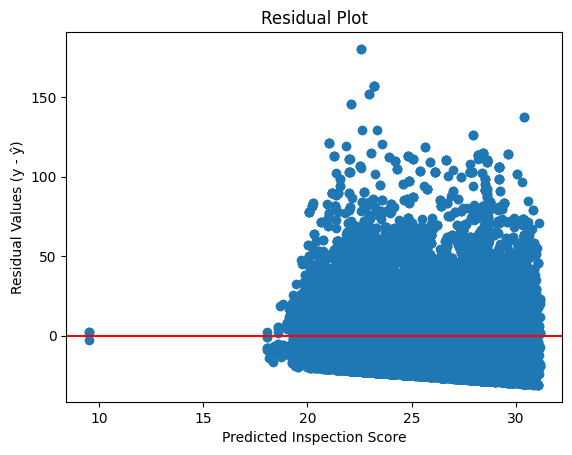

In [ ]:
# Plot the residuals

y_hat_lr = model_lr.predict(X_test_lr)
residuals_lr = y_test_lr - y_hat_lr

plt.scatter(y_hat_lr, residuals_lr)
plt.axhline(0, color='red')

plt.xlabel("Predicted Inspection Score")
plt.ylabel("Residual Values (y - ŷ)")
plt.title("Residual Plot")
plt.show()

In [ ]:
df['inspection_score'].mean()

np.float64(25.327378764938484)

**Residual plot analysis:** The residual plot reveals that most residuals are positive, indicating that the model underpredicts inspection scores. Additionally, predicted values are concentrated around the mean, suggesting that the model fails to capture data variability and is likely underfitting.

**Taking into account multicollinearity:** Multicollinearity occurs when predictor variables are highly correlated with each other which can lead to unexpected "high variance".

In our linear regression model, multicollinearity may occur between the one-hot encoded categorical variables and between latitude and longitude variables.

However, multicollinearity mainly affects how we interpret the model coefficients, not the predictive performance of the model. For our model, it seems like the core issue is the weak relationship between inspection score ratings and the numeric and categorical feature variables, not necessarily the interpretability.

**Overall analysis:** Although some variables appear to have strong positive or negative coefficients, the overall model has weak predictive power with an R^2 value of 0.025. This indicates that the model explains only about 2.5% of the variance in inspection scores. About 97.5% of the variance is unexplained by the model. Therefore, these variables by itself cannot sufficiently predict inspection scores.

**Reflecting on model choice:** In the future, it may be beneficial to explore non-linear models like Decision Trees or Random Forests, as they are able to capture more complex, non-linear relationships that Linear Regression cannot. However, the low R^2 value suggests that maybe model choice alone is not the primary limitation in predicting inspection scores. It may be that the data collected by the Department of Health and Mental Hygiene (DOHMH) does not fully capture the factors that explain the variability in the ratings.

## Feature Space Engineering (SM):

To improve upon the baseline linear regression model, we expanded the feature space by through interaction terms and aggregated features. The goal was to improve upon the performance of the raw features model based on the relationships and patterns found from the exploratory data analysis earlier. We maintained the same model type (linear regression) for fair comparison.  

We tried several feature engineering ideas, some of which improved model performance, and some of which did not. We only kept the code for the ideas that did improve the performance, but we will discuss later what the other ideas were too.

In [ ]:
# Expand the feature space of the raw features linear regression model (some code was repeated from the previous section)
X = df[['latitude', 'longitude']]
# Target variable
y = df['inspection_score']

# Single train/test split
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X, y,
    test_size=0.2,
    random_state=3001
)

# Scaling after split to prevent data leakage
scaler = MinMaxScaler()

X_train_fe.loc[:, ['latitude', 'longitude']] = scaler.fit_transform(
    X_train_fe[['latitude', 'longitude']]
) # fit_transform is used on the training data

X_test_fe.loc[:, ['latitude', 'longitude']] = scaler.transform(
    X_test_fe[['latitude', 'longitude']]
) # transform is used on the test data

# Add one-hot encoded categorical features
X_train_fe = pd.concat([X_train_fe, one_hot_encoding_mat.loc[X_train_fe.index]], axis=1)
X_test_fe = pd.concat([X_test_fe, one_hot_encoding_mat.loc[X_test_fe.index]], axis=1)

**1. Add mean inspection score by zipcode**

In the exploratory data analysis, a significant standard deviation was observed between the inspection scores by zipcode. Therefore, we had concluded that zipcode could be an important factor in predicting the inspection score for the restaurants. We created a feature representing the average inspection score for each zipcode using training data only, to help capture patterns in the inspection outcomes by regional location. This aggregation improved performance and was much more meaningful than the raw location features on their own, since it shows neighborhood-level trends.

In [ ]:
zip_mean = df.loc[X_train_fe.index].groupby('zipcode')['inspection_score'].mean()

# Map mean inspection score by zip code to train and test sets
X_train_fe['zipcode_mean'] = df.loc[X_train_fe.index, 'zipcode'].map(zip_mean)
X_test_fe['zipcode_mean'] = df.loc[X_test_fe.index, 'zipcode'].map(zip_mean)

**2. Add mean inspection score by cuisine type**

We wanted to see if the cuisine type would also give us a similar performance improvement like the zipcode did. We introduced a feature representing the average inspection score for each cuisine type using training data only. This captures  differences in inspection outcomes across cuisines. We thought this is important to consider because differences in meal prep and foods served across cuisines may have a meaningful impact on inspection outcomes. Like the zipcode, this term also helped improve performance as we anticipated.

In [ ]:
cuisine_mean = df.loc[X_train_fe.index].groupby('cuisine_type')['inspection_score'].mean()

# Map mean inspection score by cuisine type to train and test sets
X_train_fe['cuisine_mean'] = df.loc[X_train_fe.index, 'cuisine_type'].map(cuisine_mean)
X_test_fe['cuisine_mean'] = df.loc[X_test_fe.index, 'cuisine_type'].map(cuisine_mean)

X_train_fe['cuisine_mean'] = X_train_fe['cuisine_mean'].fillna(cuisine_mean.mean())
X_test_fe['cuisine_mean'] = X_test_fe['cuisine_mean'].fillna(cuisine_mean.mean())

**3. Interaction terms: borough x cuisine mean and borough x zipcode mean**

We created interaction terms between each borough and the aggregated features above. Our exploratory data analysis showed that that there was some difference (especially in outliers) in the inspection scores across boroughs, so we thought interaction terms of each borough and the aggregated features that helped improve model performance would be helpful too.


These interaction terms help the model capture how the relationship between the average score for cuisine type or neighborhood may differ depending on the borough. The strategy of combining strong features (cuisine_mean and zipcode_mean) with geographic groupings also improved performance as we anticipated.

In [ ]:
borough_cols = ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']
for col in borough_cols:
    X_train_fe[f'{col}_cuisine_mean'] = X_train_fe[col] * X_train_fe['cuisine_mean']
    X_test_fe[f'{col}_cuisine_mean'] = X_test_fe[col] * X_test_fe['cuisine_mean']

    X_train_fe[f'{col}_zipcode_mean'] = X_train_fe[col] * X_train_fe['zipcode_mean']
    X_test_fe[f'{col}_zipcode_mean'] = X_test_fe[col] * X_test_fe['zipcode_mean']

Create model and print coefficients (modified from Raw Features section)

In [ ]:
# Create the model
model_fe = LinearRegression()

# Fit the model on the training data
model_fe.fit(X_train_fe, y_train_fe)

# Print the model coefficients
coef_df_fe = pd.DataFrame({
    'Variable': X_train_fe.columns,
    'Coefficient': model_fe.coef_
})

# Sort by coefficients by magnitude (high to low values)
coef_df_fe = coef_df_fe.reindex(
    coef_df_fe['Coefficient'].abs().sort_values(ascending=False).index
)

print(coef_df_fe)
print('\nModel Intercept:', model_fe.intercept_)

# In linear regression, one variable is dropped to be used as the baseline to help avoid perfect multicollinearity ("dummy variable trap")

                          Variable  Coefficient
4                        Manhattan    -5.289286
6                    Staten Island     3.325362
1                        longitude    -3.076391
12                          French     3.003634
2                            Bronx     2.377933
0                         latitude     1.401815
5                           Queens    -1.355586
3                         Brooklyn     0.941578
24                      Vegitarian    -0.754061
26                    cuisine_mean     0.704543
25                    zipcode_mean     0.682723
17                         Oceania     0.633032
21         Soups/Salads/Sandwiches     0.497355
11                        European     0.452382
20                         Seafood     0.445854
7                         American     0.421113
31          Manhattan_cuisine_mean     0.391867
18                           Pizza     0.383684
9                        Breakfast    -0.279279
8                            Asian    -0

In [ ]:
# Function for MSE
def MSE(y_true, y_hat):

  # Calculate the squared errors
  squared_errors = (y_hat - y_true)**2

  # Calculate the mean of the squared errors
  mean_squared_errors = np.sum(squared_errors) / len(y_true)

  return mean_squared_errors

In [ ]:
# Evaluate the model's performance

# Predictions
y_train_pred_fe = model_fe.predict(X_train_fe)
y_test_pred_fe = model_fe.predict(X_test_fe)

# MSE values
train_mse_fe = MSE(y_train_fe, y_train_pred_fe)
test_mse_fe = MSE(y_test_fe, y_test_pred_fe)

# Convert to RMSE
train_rmse_fe = np.sqrt(train_mse_fe)
test_rmse_fe = np.sqrt(test_mse_fe)

# R^2 values
train_r2_fe = model_fe.score(X_train_fe, y_train_fe)
test_r2_fe = model_fe.score(X_test_fe, y_test_fe)

# Print the results
print('Expanded Feature Space Model Performance:')
print('Train RMSE:', train_rmse_fe)
print('Test RMSE:', test_rmse_fe)
print('Train R^2:', train_r2_fe)
print('Test R^2:', test_r2_fe)

Expanded Feature Space Model Performance:
Train RMSE: 18.30052447918315
Test RMSE: 18.37498640032036
Train R^2: 0.05445980405200346
Test R^2: 0.05256582111331842


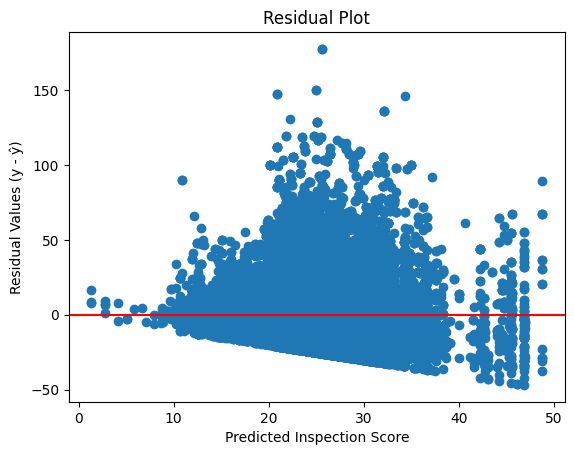

In [ ]:
# Plot the residuals

y_hat_fe = model_fe.predict(X_test_fe)
residuals_fe = y_test_fe - y_hat_fe

plt.scatter(y_hat_fe, residuals_fe)
plt.axhline(0, color='red')

plt.xlabel("Predicted Inspection Score")
plt.ylabel("Residual Values (y - ŷ)")
plt.title("Residual Plot")
plt.show()

**Conclusion:**

The expanded feature space model shows a modest but consistent improvement over the baseline raw features model. The expanded feature space model had a test RMSE of ~18.38 and a test R^2 of ~0.051, compared to the raw features test RMSE of ~18.63 and a test R^2 of ~0.025. The improvement may not have been large, but it was really meaningful to see significantly more improvement when we tried ideas tied to features we found meaningful in the EDA step, compared to ideas related to features we had not found meaningful previously.

To further elaborate on that, some ideas we tried which barely improved perfomance were creating a polynomial expansion of latitude and longitude, and creating interaction terms between borough and latitude/longitude. This was consistent with our conclusion in the EDA that there was no observed relationship between latitude and longitude.

To that end, when we introduced the feature of zipcode mean, the performance significantly improved compared to how it was for the latitude/longitude feature expansions, which matched our earlier findings where the inspection scores by zipcode had a high standard deviation.

We believed the interaction terms between borough and latitude/longitude were barely improving performance, since the latitude/longitude features were not strong predictors themselves. Once we saw zipcode mean and cuisine mean were strong predictors, we created interaction terms between borough and these features, which did improve performance. We learned that interaction terms are more effective when the variable the interaction is being created on is a strong predictor.


Lastly, there was no evidence of overfitting from these expansions, because the results were very close between both training and test sets. This suggests that the added features capture real patterns rather than noise. The residual plots further support this, since the residuals are generally centered around zero, indicating less bias from the model. However, some noticeable spread means that this model still has many patterns it can still learn to improve.


## Fit At Least One Different Model Family (KS):


**Model choice:** We chose to test KNN as the only different model family, since KNN provides insight into another framework of assumptions that have not been explored yet. The comparison is meaningful because if KNN fits the model better, it may indicate the presence of a nonlinear structure in the data.  Linear regression and KNN have two sets of assumptions, and by fitting the different models, we depict how inspection scores vary between models. Linear regression assumes a linear relationship between the features and the target variable; however, KNN assumes that points nearby in the feature space have similar inspection scores. To fit the KNN, we must determine the number of k through k-fold cross-validation, use MinMaxScaling, since KNN is spatial-based, thus we need to ensure that the values are on the same scale, as well as address the sheer amount of observations in the dataset (296k), which can be dealt with through sampling within the total amount of samples, assuming the samples are iid and are representative of the true population.


In [ ]:
# Import Statement
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.preprocessing import MinMaxScaler

**Subsetting Data:** Because the sample size in the data set is large, with 296k observations, this makes the computation difficult. However, we can remedy this by subsetting the data to only compute 30%, which is still "large" enough to show the true trend in data, has an approximate distribution of the inspection scores, and allows for cross-validation computation in a reasonable runtime.

In [ ]:
# Create random state for reproducibility - 3001 for DS 3001
random_state = 3001

# Determine sample size for subsetting data- computationally too large for the hyperparameter section
sample_size = 100000

# Read in the data frame and sample
df_k = pd.read_csv('DOHMH_New_York_City_Restaurant_Inspection_Results_20260312.csv', low_memory= False)
df_k = df_k.sample(n=sample_size, random_state=random_state)

# Drop the leakage columns
df_k = df_k.drop(columns=['critical_flag', 'violation_code', 'violation_description', 'action',
                            'GRADE', 'GRADE DATE', 'RECORD DATE', 'BIN', 'Census Tract',
                            'NTA', 'DBA', 'PHONE', 'BUILDING', 'STREET', 'Location',
                            'VIOLATION CODE', 'VIOLATION DESCRIPTION', 'ACTION',
                            'CRITICAL FLAG', 'CAMIS', 'BBL'], errors='ignore')

# Head the dataframe
df_k.head()

,BORO,ZIPCODE,CUISINE DESCRIPTION,INSPECTION DATE,SCORE,INSPECTION TYPE,Latitude,Longitude,Community Board,Council District
52,Queens,11430.0,Sandwiches/Salads/Mixed Buffet,12/7/2016,0.0,Cycle Inspection / Initial Inspection,NaN,NaN,NaN,NaN
125193,Manhattan,10002.0,Chinese,10/17/2024,90.0,Cycle Inspection / Initial Inspection,40.718396,-73.994665,103.0,1.0
233781,Queens,11106.0,Coffee/Tea,4/27/2023,27.0,Pre-permit (Operational) / Initial Inspection,40.758060,-73.928353,401.0,22.0
126776,Queens,11385.0,Chinese,11/4/2024,10.0,Cycle Inspection / Initial Inspection,40.700359,-73.905438,405.0,34.0
250326,Queens,11354.0,Chinese,12/7/2022,57.0,Pre-permit (Operational) / Re-inspection,40.759088,-73.834175,407.0,20.0


In [ ]:
# Create the X, y variables
X = df_k.drop(columns=['SCORE'])
y = df_k['SCORE']

**Test Train Split:** We are still using the same design matrix as in part 1, where we considered the scaled version of longitude/latitude, one-hot encoded version of boroughs, and cuisine type. We are also using scaling to ensure that the KNN, which computes distances. Without scaling, if a certain observation has a large range, then it would dominate the distances, making the other distances less meaningful. We can use the 80/20 split ratio and the same random state as part 1 to ensure the comparison is valid.

In [ ]:
# Create test train split

X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(
    X, y,
    test_size=0.2,
    random_state=random_state)

**Reformatting the Data** The KNN model requires that the object type be transformed into strings, so for each of the columns where the type is 'object' in the y_test, y_train, X_test, X_train, they were changed to strings through a LabelEncoder. In addition, KNN does not handle NAs, so we dropped NA values before fitting the model to ensure there were no errors.

In [ ]:
# Reformat the Data Before Choosing K
from sklearn.preprocessing import LabelEncoder

# TRAIN DATA
# Copying the train data to avoid modifying original data split
X_train_encoded = X_train_knn.copy()
y_train_encoded = y_train_knn.copy()

# Create empty dictionary to store the LabelEncoder per each variable in the cateogrical column
encoders = {}

# Loop over each column in the X_train that has the data type of an object
for col in X_train_encoded.select_dtypes(include='object').columns:
# Create a new LabelEncoder for the column
    le = LabelEncoder()
# Using fit_transform to conver them to integers
# Astype ensures there are no mixed data types
    X_train_encoded[col] = le.fit_transform(X_train_encoded[col].astype(str))
# Saving the fitted encoder to apply the same pattern to the test set
    encoders[col] = le

# Combine the X and y into one dataframe so that the rows that were dropped are still aligned
train_data_knn = X_train_encoded.copy()
train_data_knn['target'] = y_train_encoded

# Drop any rows with NA and then rest the index
# Reset_index ensures that the index is clean after dropping the rows
train_data_knn = train_data_knn.dropna().reset_index(drop=True)

# Splitting the X and y train back apart since NA are removed and indexes are realigned
X_train_encoded = train_data_knn.drop(columns=['target'])
y_train_encoded = train_data_knn['target']

# TEST DATA
# Copy the test data to avoid modifying the original data split
X_test_encoded = X_test_knn.copy()
y_test_encoded = y_test_knn.copy()

# Iterate over the categorical columns and drop the rows where the test set has a category
# It has not encountered in training bc LabelEncoder cannot assign a value if it has not seen
# The label before, so we drop them.
for col in X_test_encoded.select_dtypes(include='object').columns:

# Get the set of categories that the encoder got from the training data
    known = set(encoders[col].classes_)

# Create a boolean mask: T if known, F else
    mask = X_test_encoded[col].astype(str).isin(known)
    X_test_encoded = X_test_encoded[mask]
    y_test_encoded = y_test_encoded[mask]

# Applt the train encoders to the test categorical variables
# Use transform so the integer mapping is identificla to the train process
for col in X_test_encoded.select_dtypes(include='object').columns:
    X_test_encoded[col] = encoders[col].transform(X_test_encoded[col].astype(str))

# Combine the X and Y into one dataframe so the rows that we dropped stays aligned between them
test_data_knn = X_test_encoded.copy()
test_data_knn['target'] = y_test_encoded

# Drop any row that has an NA value and reset the index
test_data_knn = test_data_knn.dropna().reset_index(drop=True)

# Split the X and Y test back apart since the NA values were removed and indexes were realigned
X_test_encoded = test_data_knn.drop(columns=['target'])
y_test_encoded = test_data_knn['target']

**Choosing K:** After creating the test and train split, we can proceed to choosing our k for the value. While picking k, we must consider the bias-variance tradeoff. When k is small, there is low bias and high variance, which causes the model to overfit to the noise. However, with large k, the model has high bias and low variance, thus underfitting the data. We can use k-fold cross-validation to select the best k for the model. Once we select the optimal k value, we can also plot it to visualize the different aspects of how k impacts the model.

In [ ]:
# Import Libraries
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler

In [ ]:
# Scale the data
scaler = MinMaxScaler()
X_train_encoded = pd.DataFrame(scaler.fit_transform(X_train_encoded), columns=X_train_encoded.columns)
X_test_encoded = pd.DataFrame(scaler.transform(X_test_encoded), columns=X_test_encoded.columns)

# Create a list of k values (# to try)
k_values = [2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100]

# Store the mean cross validation RMSE for each fold of k
validation_rmse = []

# Create 10-fold cross validation with shuffling
kf = KFold(n_splits=10, shuffle=True, random_state=random_state)

# Try each value of k through the loop
# KNN regressor with the current k
# Hold the RMSE with blank list
for k in k_values:
  knn = KNeighborsRegressor(n_neighbors=k)
  fold_rmse = []

# After (fixed) — use X_train_encoded everywhere
# Index the training fold rows using positional indexes
# Go over each train/validation fold split
  for train_index, val_index in kf.split(X_train_encoded):
      X_train_fold = X_train_encoded.iloc[train_index]
      y_train_fold = y_train_encoded.iloc[train_index]

# Slice the validation fold rows
      X_val_fold = X_train_encoded.iloc[val_index]
      y_val_fold = y_train_encoded.iloc[val_index]

# Train the KNN model on the fold's training data
      knn.fit(X_train_fold, y_train_fold)
      pred = knn.predict(X_val_fold)

# Compute RMSE for the fold and append to thes list
      rmse = np.sqrt(mean_squared_error(y_val_fold, pred))
      fold_rmse.append(rmse)

# Average RMSE across all 10 folds for this k
# Store mean RMSE for this k
  mean_rmse = np.mean(fold_rmse)
  validation_rmse.append(mean_rmse)
  print(f" k= {k:>4}| CV RMSE: {mean_rmse:.4f}")

# Selct the optimal K
best_k = k_values[np.argmin(validation_rmse)]
print(f"Optimal k: {best_k}")

 k=    2| CV RMSE: 14.9086
 k=    3| CV RMSE: 15.8240
 k=    5| CV RMSE: 16.8915
 k=    7| CV RMSE: 17.3800
 k=   10| CV RMSE: 17.7515
 k=   15| CV RMSE: 18.0174
 k=   20| CV RMSE: 18.1292
 k=   30| CV RMSE: 18.2345
 k=   50| CV RMSE: 18.3295
 k=   75| CV RMSE: 18.3900
 k=  100| CV RMSE: 18.4162
Optimal k: 2


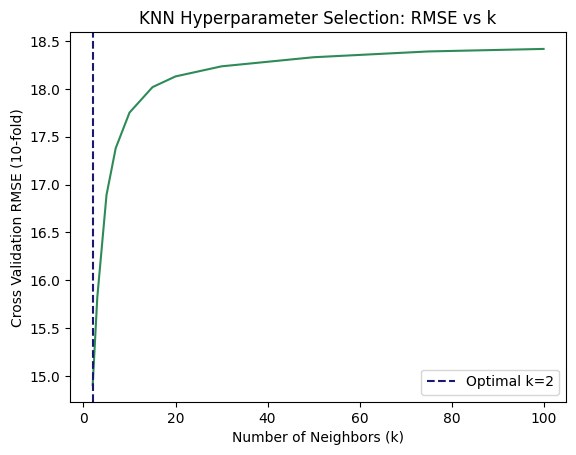

In [ ]:
# Create plot to show the Cross Validation RMSE VS the k-value
plt.plot(k_values, validation_rmse, color='seagreen')
plt.axvline(x=best_k, color='midnightblue', linestyle='--', label=f'Optimal k={best_k}')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Cross Validation RMSE (10-fold)')
plt.title('KNN Hyperparameter Selection: RMSE vs k')
plt.legend()
plt.show()

**Fitting the Final Model:** Once we selected K through cross-validation, we can fit the model on the full training set and then evaluate on the test set, which calculates the y-predicted values.

In [ ]:
# Fitting the Final Model

# Use the KNeighborsRegressor for the model
knn_model = KNeighborsRegressor(n_neighbors=best_k)
knn_model.fit(X_train_encoded, y_train_encoded)

# Predictions for test data
y_pred_knn = knn_model.predict(X_test_encoded)

**Evaluating the Model:** We can calculate the RMSE and R-squared, which we can compare to the model created in the first part. The RMSE is the average prediction error in the original units, meaning the lower the value, the better. For R-squared, it is the proportion of variance in the expectation score explained by the model, so the higher the better. The optimal value of k is displayed below, as well as a plot of the predicted versus actual values of inpsection scores based on the y_test values and the y_predicted values to best visualize the accuracy of the model.

Optimal Value of K: 2
RMSE: 14.1694
R-Squared: 0.4309


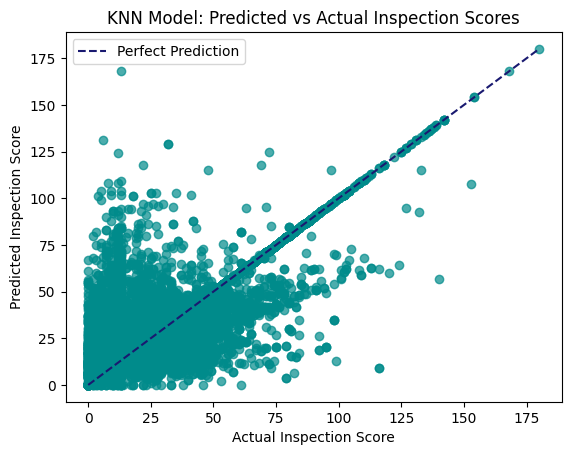

In [ ]:
# Evaluating the model

# Calculating RMSE
rmse_knn = np.sqrt(mean_squared_error(y_test_encoded, y_pred_knn))

# Calculating R-squared
r2_knn = knn_model.score(X_test_encoded, y_test_encoded)

# Printing the best k, RMSE, r-squared
print(f"Optimal Value of K: {best_k}")
print(f"RMSE: {rmse_knn:.4f}")
print(f"R-Squared: {r2_knn:.4f}")

# Plotting the predicted vs actual for the KNN with y_test_encoded, y_pred
plt.scatter(y_test_encoded, y_pred_knn, alpha = 0.7, color = "darkcyan")
plt.plot([y_test_encoded.min(), y_test_encoded.max()],[y_test_encoded.min(), y_test_encoded.max()],color='midnightblue', linestyle='--', label='Perfect Prediction')
plt.legend()
plt.xlabel("Actual Inspection Score")
plt.ylabel("Predicted Inspection Score")
plt.title("KNN Model: Predicted vs Actual Inspection Scores")
plt.show()

**Conclusion:** Through fitting the KNN model, we were able to determine the RMSE and R-squared value, which we can directly compare to the Linear Regression model. In addition, we also determined the optimal value of K, which was 2 (in the model used to explain). The KNN model has an RMSE of 14.1694, meaning the average predicted error of the inspection score is off by 14.1694 points. The R-squared value is moderate, 0.4309. 43.09% of the variance in inspection score can be explained by the model. Meanwhile, the linear regression model had a test RMSE of 18.47 and an R-squared of 0.04, suggesting the  KNN neighbor may have the model slightly better, especially considering the R-squared value.

## Consider Alternative Models (SL):

Our linear regression model had weak predictive power (R² ≈ 0.025), while KNN improved substantially (R² ≈ 0.431), suggesting non-linear relationships exist in the data. We now explore two additional model families:

1. **Decision Tree Regressor** — captures non-linear, hierarchical splits and is interpretable via its dendrogram and feature importances.
2. **Random Forest Regressor** — an ensemble of decision trees that reduces the overfitting tendency of a single tree through bootstrap aggregation and random feature selection.

We use the same 100,000-observation sample, 80/20 train/test split, and `random_state=3001` as in the KNN section for comparability.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

# Same sample setup as KNN section
random_state = 3001
sample_size = 100000

df_alt = pd.read_csv('DOHMH_New_York_City_Restaurant_Inspection_Results_20260312.csv')
df_alt = df_alt.sample(n=sample_size, random_state=random_state)

# Drop leakage columns
df_alt = df_alt.drop(
    columns=['critical_flag', 'violation_code', 'violation_description', 'action',
             'GRADE', 'GRADE DATE', 'RECORD DATE', 'BIN', 'Census Tract',
             'NTA', 'DBA', 'PHONE', 'BUILDING', 'STREET', 'Location',
             'VIOLATION CODE', 'VIOLATION DESCRIPTION', 'ACTION',
             'CRITICAL FLAG', 'CAMIS', 'BBL'],
    errors='ignore'
)

# Drop rows missing the target
df_alt = df_alt.dropna(subset=['SCORE'])

# Feature / target split
X_alt = df_alt.drop(columns=['SCORE'])
y_alt = df_alt['SCORE']

# Label-encode all object columns (same approach as KNN section)
encoders_alt = {}
for col in X_alt.select_dtypes(include='object').columns:
    le = LabelEncoder()
    X_alt[col] = le.fit_transform(X_alt[col].astype(str))
    encoders_alt[col] = le

X_alt = X_alt.fillna(X_alt.median(numeric_only=True))

# Train/test split
X_train_alt, X_test_alt, y_train_alt, y_test_alt = train_test_split(
    X_alt, y_alt,
    test_size=0.2,
    random_state=random_state
)

print("Train size:", X_train_alt.shape, "| Test size:", X_test_alt.shape)

/tmp/ipykernel_2863/2643497440.py:9: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df_alt = pd.read_csv('DOHMH_New_York_City_Restaurant_Inspection_Results_20260312.csv')


Train size: (75541, 9) | Test size: (18886, 9)


  max_depth=3    | Train RMSE: 18.4731 | Test RMSE: 18.6040
  max_depth=5    | Train RMSE: 18.2902 | Test RMSE: 18.5216
  max_depth=8    | Train RMSE: 17.8217 | Test RMSE: 18.1948
  max_depth=10   | Train RMSE: 17.1511 | Test RMSE: 17.8644
  max_depth=15   | Train RMSE: 13.9289 | Test RMSE: 16.2936
  max_depth=20   | Train RMSE: 9.8361 | Test RMSE: 14.8062


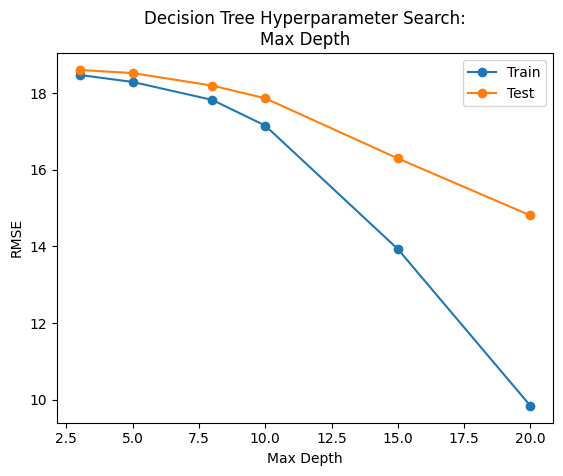

Optimal max_depth: 20


In [ ]:
# Tune max_depth by comparing train vs test RMSE
depth_values = [3, 5, 8, 10, 15, 20]

train_rmse_dt = []
test_rmse_dt = []

for depth in depth_values:
    cart = DecisionTreeRegressor(max_depth=depth, random_state=random_state)
    cart = cart.fit(X_train_alt, y_train_alt)

    y_hat_train = cart.predict(X_train_alt)
    y_hat_test = cart.predict(X_test_alt)

    train_rmse = np.sqrt(mean_squared_error(y_train_alt, y_hat_train))
    test_rmse = np.sqrt(mean_squared_error(y_test_alt, y_hat_test))

    train_rmse_dt.append(train_rmse)
    test_rmse_dt.append(test_rmse)

    print(f"  max_depth={depth:<4} | Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f}")

# Plot the results
plt.plot(depth_values, train_rmse_dt, label='Train', marker='o')
plt.plot(depth_values, test_rmse_dt, label='Test', marker='o')
plt.xlabel('Max Depth')
plt.ylabel('RMSE')
plt.title('Decision Tree Hyperparameter Search:\nMax Depth')
plt.legend()
plt.show()

# Select the depth with the lowest test RMSE
best_depth = depth_values[np.argmin(test_rmse_dt)]
print(f"Optimal max_depth: {best_depth}")

Optimal max_depth: 20
Decision Tree Test RMSE: 14.8062
Decision Tree Test R²: 0.3883


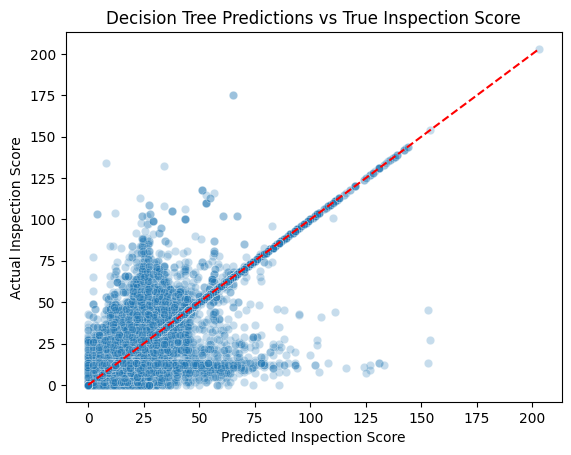

In [ ]:
# Fit the final decision tree using the optimal max_depth
cart = DecisionTreeRegressor(max_depth=best_depth, random_state=random_state)
cart = cart.fit(X_train_alt, y_train_alt)

# Predictions
y_hat_dt = cart.predict(X_test_alt)

# Metrics
rmse_dt = np.sqrt(mean_squared_error(y_test_alt, y_hat_dt))
r2_dt = cart.score(X_test_alt, y_test_alt)

print(f"Optimal max_depth: {best_depth}")
print(f"Decision Tree Test RMSE: {rmse_dt:.4f}")
print(f"Decision Tree Test R²: {r2_dt:.4f}")

# Predicted vs Actual plot
sns.scatterplot(
    y=y_test_alt,
    x=y_hat_dt,
    alpha=0.25
)
plt.title('Decision Tree Predictions vs True Inspection Score')
plt.xlabel('Predicted Inspection Score')
plt.ylabel('Actual Inspection Score')

x_min = min(y_hat_dt)
x_max = max(y_hat_dt)
plt.plot([x_min, x_max], [x_min, x_max], color='red', linestyle='--')
plt.show()

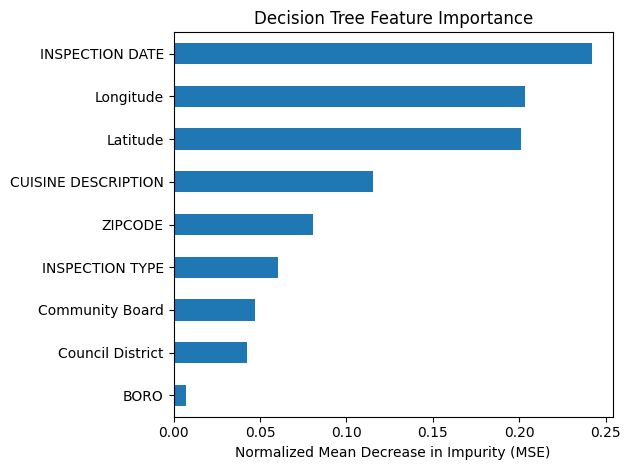

In [ ]:
# Feature importance for the decision tree
feature_importances_series = pd.Series(
    cart.feature_importances_,
    index=X_train_alt.columns
)

# Sort the values
feature_importances_series = feature_importances_series.sort_values()

# Plot as horizontal bar chart
feature_importances_series.tail(10).plot(kind='barh')
plt.title('Decision Tree Feature Importance')
plt.xlabel('Normalized Mean Decrease in Impurity (MSE)')
plt.tight_layout()
plt.show()

  min_samples_leaf=10   | Train RMSE: 13.3945 | Test RMSE: 15.3261
  min_samples_leaf=25   | Train RMSE: 15.5119 | Test RMSE: 16.6139
  min_samples_leaf=50   | Train RMSE: 16.6130 | Test RMSE: 17.2870
  min_samples_leaf=75   | Train RMSE: 17.0782 | Test RMSE: 17.5732
  min_samples_leaf=100  | Train RMSE: 17.3295 | Test RMSE: 17.7254


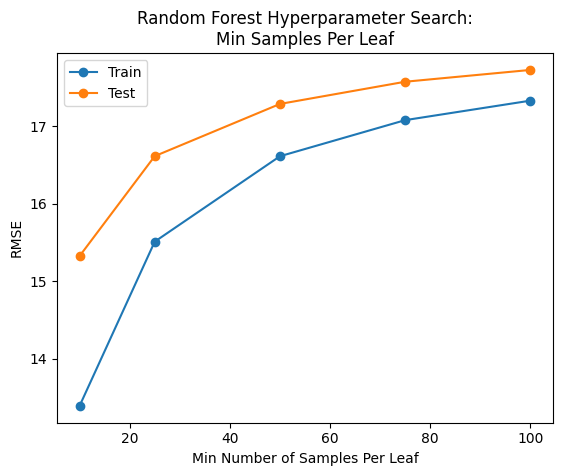

Optimal min_samples_leaf: 10


In [ ]:
# Tune min_samples_leaf for Random Forest
min_samples_values = [10, 25, 50, 75, 100]

train_rmse_rf = []
test_rmse_rf = []

for min_sample in min_samples_values:
    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=best_depth,
        min_samples_leaf=min_sample,
        random_state=random_state,
        n_jobs=-1
    )
    rf = rf.fit(X_train_alt, y_train_alt)

    y_hat_train = rf.predict(X_train_alt)
    y_hat_test = rf.predict(X_test_alt)

    train_rmse = np.sqrt(mean_squared_error(y_train_alt, y_hat_train))
    test_rmse = np.sqrt(mean_squared_error(y_test_alt, y_hat_test))

    train_rmse_rf.append(train_rmse)
    test_rmse_rf.append(test_rmse)

    print(f"  min_samples_leaf={min_sample:<4} | Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f}")

# Plot the results
plt.plot(min_samples_values, train_rmse_rf, label='Train', marker='o')
plt.plot(min_samples_values, test_rmse_rf, label='Test', marker='o')
plt.xlabel('Min Number of Samples Per Leaf')
plt.ylabel('RMSE')
plt.title('Random Forest Hyperparameter Search:\nMin Samples Per Leaf')
plt.legend()
plt.show()

best_min_samples = min_samples_values[np.argmin(test_rmse_rf)]
print(f"Optimal min_samples_leaf: {best_min_samples}")

Optimal min_samples_leaf: 10
Random Forest Test RMSE: 15.3261
Random Forest Test R²: 0.3446


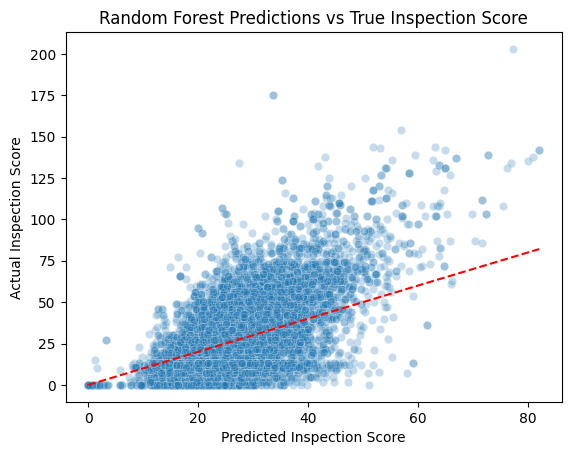

In [ ]:
# Fit the final Random Forest using optimal hyperparameters
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=best_depth,
    min_samples_leaf=best_min_samples,
    random_state=random_state,
    n_jobs=-1
)
rf = rf.fit(X_train_alt, y_train_alt)

# Predictions
y_hat_rf = rf.predict(X_test_alt)

# Metrics
rmse_rf = np.sqrt(mean_squared_error(y_test_alt, y_hat_rf))
r2_rf = rf.score(X_test_alt, y_test_alt)

print(f"Optimal min_samples_leaf: {best_min_samples}")
print(f"Random Forest Test RMSE: {rmse_rf:.4f}")
print(f"Random Forest Test R²: {r2_rf:.4f}")

# Predicted vs Actual plot
sns.scatterplot(
    y=y_test_alt,
    x=y_hat_rf,
    alpha=0.25
)
plt.title('Random Forest Predictions vs True Inspection Score')
plt.xlabel('Predicted Inspection Score')
plt.ylabel('Actual Inspection Score')

x_min = min(y_hat_rf)
x_max = max(y_hat_rf)
plt.plot([x_min, x_max], [x_min, x_max], color='red', linestyle='--')
plt.show()

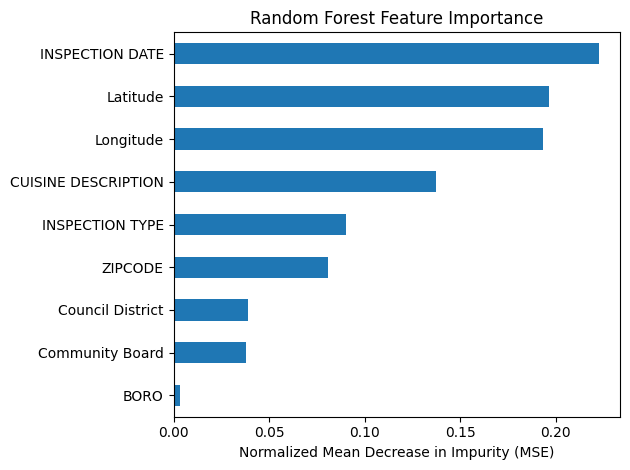

In [ ]:
# Feature importance for the random forest
feature_importances_series = pd.Series(
    rf.feature_importances_,
    index=X_train_alt.columns
)

# Sort the values
feature_importances_series = feature_importances_series.sort_values()

# Plot as horizontal bar chart
feature_importances_series.tail(10).plot(kind='barh')
plt.title('Random Forest Feature Importance')
plt.xlabel('Normalized Mean Decrease in Impurity (MSE)')
plt.tight_layout()
plt.show()

## Compare All Models You Created (HM):

Now that we have finished fitting all of our models, we want to compare them and find which model predicted the inspection score the best. To figure out which model is the best, we are going to perform hyper parameter tuning (grid search) to find the parameters that give us the optimal metrics for each of the models. Grid searches are a optimization technique used to find the best paramter combinations for a particular model. Once we find the best parameters and apply them to the model, we will compare the R^2, MSE, and RMSE.

**Linear Regression with Raw Features**


We started out by doing a hyperparameter search for the linear regression model that only included the raw features. As we are conducting a grid search, it utilizes cvs to optimize the parameters. Linear regression, in general, does not have a lot of parameters to tune. We have copy_X, fit_intercept, n_jobs, and positive. N_jobs means the numebr of jobs that is going into the computation, fit_intercept is whether our model should have an intercept value, copy_X is whether our predictors will be copied or overwritten, and positive is whether all coefficeints will be forced to be positive. This grid search shows that the best parameters are copy_X is True, fit_intercept is True, n_jobs is 1, and positive is False.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_space = {'copy_X': [True,False], 'fit_intercept': [True,False], 'n_jobs': [1,5,10,15,None], 'positive': [True,False]}

lr_grid_search = GridSearchCV(
    model_lr,
    param_space,
    cv=5,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error",
        "mse": "neg_mean_squared_error"
    },
    refit="rmse"   # choose the metric used to pick the final best model
)

lr_grid_search.fit(X_train_lr, y_train_lr)

print("Best params:", lr_grid_search.best_params_)
print("Best CV R^2:", lr_grid_search.cv_results_["mean_test_r2"][lr_grid_search.best_index_])
print("Best CV RMSE:", -lr_grid_search.cv_results_["mean_test_rmse"][lr_grid_search.best_index_])
print("Best CV MSE:", -lr_grid_search.cv_results_["mean_test_mse"][lr_grid_search.best_index_])

Best params: {'copy_X': True, 'fit_intercept': True, 'n_jobs': 1, 'positive': False}
Best CV R^2: 0.02529560342674031
Best CV RMSE: 18.5797262738907
Best CV MSE: 345.21900435439494


From the grid search, we see that the model with the best parameters give us an R^2 of 0.025, RMSE of 18.56, and a MSE of 344.45. These are slightly better metrics than the model without the hyperparameter search, but not by much. This is due to the fact that our grid search told us most of the best parameters were the default values. The only parameter that was different than the default was n_jobs which had 1 instead of None.

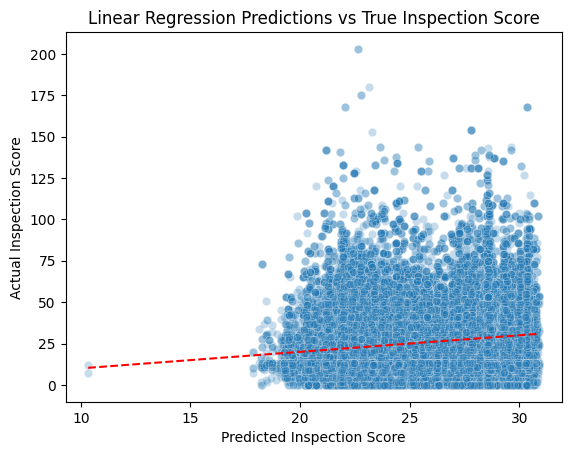

In [ ]:
# Predictions
model = LinearRegression(
    copy_X=True,
    fit_intercept=True,
    n_jobs = 1,
    positive = False
)

model.fit(X_train_lr, y_train_lr)

y_pred = model.predict(X_test_lr)

y_hat = model.predict(X_test_lr)

# Predicted vs Actual plot
sns.scatterplot(
    y=y_test_lr,
    x=y_pred,
    alpha=0.25
)
plt.title('Linear Regression Predictions vs True Inspection Score')
plt.xlabel('Predicted Inspection Score')
plt.ylabel('Actual Inspection Score')

x_min = min(y_hat)
x_max = max(y_hat)
plt.plot([x_min, x_max], [x_min, x_max], color='red', linestyle='--')
plt.show()

**Linear Regression Model with Feature Engineered Features**

For the Linear Regression model with feature engineered features, the procedure will be the same. We will be conducting a grid search to look in the best parameter values for copy_X, fit_intercept, n_jobs, and positive. This grid search shows that the best parameters are copy_X is True, fit_intercept is True, n_jobs is 1, and positive is False.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_space = {'copy_X': [True,False], 'fit_intercept': [True,False], 'n_jobs': [1,5,10,15,None], 'positive': [True,False]}

fe_grid_search = GridSearchCV(
    model_fe,
    param_space,
    cv=5,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error",
        "mse": "neg_mean_squared_error"
    },
    refit="rmse"   # choose the metric used to pick the final best model
)

fe_grid_search.fit(X_train_fe, y_train_fe)

print("Best params:", fe_grid_search.best_params_)
print("Best CV R^2:", fe_grid_search.cv_results_["mean_test_r2"][fe_grid_search.best_index_])
print("Best CV RMSE:", -fe_grid_search.cv_results_["mean_test_rmse"][fe_grid_search.best_index_])
print("Best CV MSE:", -fe_grid_search.cv_results_["mean_test_mse"][fe_grid_search.best_index_])

Best params: {'copy_X': True, 'fit_intercept': True, 'n_jobs': 1, 'positive': False}
Best CV R^2: 0.05400412587457237
Best CV RMSE: 18.30403662558036
Best CV MSE: 335.04928286276373


From the grid search, we see that the model with the best parameters give us an R^2 of 0.05, RMSE of 18.29, and a MSE of 334.45.

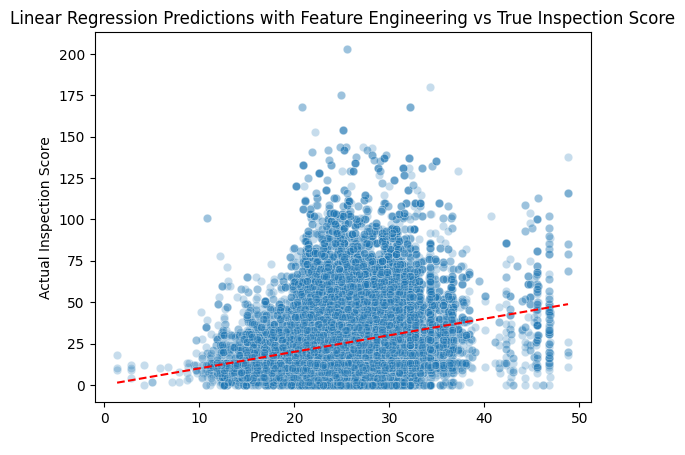

In [ ]:
# Predictions
model = LinearRegression(
    copy_X=True,
    fit_intercept=True,
    n_jobs = 1,
    positive = False
)

model.fit(X_train_fe, y_train_fe)

y_pred = model.predict(X_test_fe)

y_hat = model.predict(X_test_fe)

# Predicted vs Actual plot
sns.scatterplot(
    y=y_test_fe,
    x=y_pred,
    alpha=0.25
)
plt.title('Linear Regression Predictions with Feature Engineering vs True Inspection Score')
plt.xlabel('Predicted Inspection Score')
plt.ylabel('Actual Inspection Score')

x_min = min(y_hat)
x_max = max(y_hat)
plt.plot([x_min, x_max], [x_min, x_max], color='red', linestyle='--')
plt.show()

**KNN Model**

We search for the optimal hyperparameters for the KNN in a similar fashion. This time, we are focusing on three different parameters: weights, metric, and n_neighbors. Weights represents the weight funciton that will be used, metric is the how the distance is copmuted, and n_neighbors is the number of neighbors used. After running our KNN through the grid search, we find that the best parameters are "euclidean" metric, "distance" weights, and 55 neighbors.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_space = {'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan', 'minkowski'], 'n_neighbors': [5,15,25,35,45,55]}

knn_grid_search = GridSearchCV(
    knn_model,
    param_space,
    cv=5,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error",
        "mse": "neg_mean_squared_error"
    },
    refit="rmse"   # choose the metric used to pick the final best model
)

knn_grid_search.fit(X_train_encoded, y_train_encoded)

print("Best params:", knn_grid_search.best_params_)
print("Best CV R^2:", knn_grid_search.cv_results_["mean_test_r2"][knn_grid_search.best_index_])
print("Best CV RMSE:", -knn_grid_search.cv_results_["mean_test_rmse"][knn_grid_search.best_index_])
print("Best CV MSE:", -knn_grid_search.cv_results_["mean_test_mse"][knn_grid_search.best_index_])


Best params: {'metric': 'euclidean', 'n_neighbors': 55, 'weights': 'distance'}
Best CV R^2: 0.6644813538744352
Best CV RMSE: 10.917030067040832
Best CV MSE: 119.18368974651298


By using these parameters, we still that the best parameters give us a R^2 of 0.66, a RMSE of 10.92, and a MSE of 119.18.

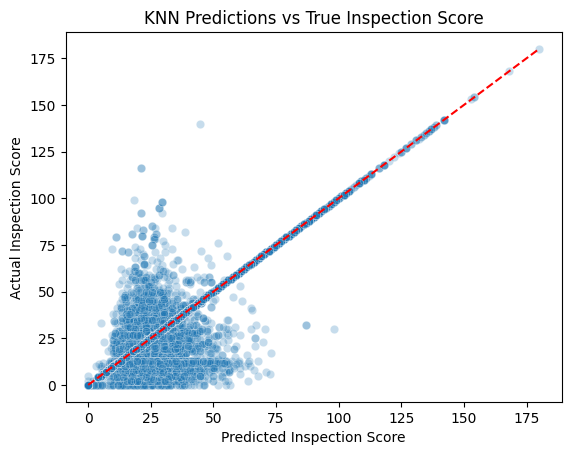

In [ ]:
# Predictions
model = KNeighborsRegressor(
    metric='manhattan',
    n_neighbors=15,
    weights = 'distance'
)

model.fit(X_train_encoded, y_train_encoded)

y_pred = model.predict(X_test_encoded)

y_hat = model.predict(X_test_encoded)

# Predicted vs Actual plot
sns.scatterplot(
    y=y_test_encoded,
    x=y_pred,
    alpha=0.25
)
plt.title('KNN Predictions vs True Inspection Score')
plt.xlabel('Predicted Inspection Score')
plt.ylabel('Actual Inspection Score')

x_min = min(y_hat)
x_max = max(y_hat)
plt.plot([x_min, x_max], [x_min, x_max], color='red', linestyle='--')
plt.show()

**Decision Tree Regressor**

We are, once again, using a grid search to find the best parameters for the decision tree model. This time, we are looking at max_depth, min_samples_split, min_samples_leaf, max_features, and ccp_alpha. Max depth is the max_depth of the tree, max_samples_leaf is the minimum amount of samples to split an internal node, max_samples_leaf is the minimum amount of samples in order for a category to be considered a leaf, max_features is the max number of features our model will look at, and ccp_alpha is the complexity parameter used for Minimal Cost-Complexity Pruning. In this case the best parameters for the model were ccp_alpha:0.0, max_depth:None, max_features:sqrt, min_samples_leaf:1, and min_samples_split:2.

In [ ]:
param_space = {
    "max_depth": [None, 4, 7, 10],
    "min_samples_split": [2, 4, 6],
    "min_samples_leaf": [1, 3, 5],
    "max_features": [None, "sqrt", "log2"],
    "ccp_alpha": [0.0, 0.01, 0.1]
}
dt_grid_search = GridSearchCV(
    cart,
    param_space,
    cv=5,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error",
        "mse": "neg_mean_squared_error"
    },
    refit="rmse"   # choose the metric used to pick the final best model
)

dt_grid_search.fit(X_train_alt, y_train_alt)

print("Best params:", dt_grid_search.best_params_)
print("Best CV R^2:", dt_grid_search.cv_results_["mean_test_r2"][dt_grid_search.best_index_])
print("Best CV RMSE:", -dt_grid_search.cv_results_["mean_test_rmse"][dt_grid_search.best_index_])
print("Best CV MSE:", -dt_grid_search.cv_results_["mean_test_mse"][dt_grid_search.best_index_])

Best params: {'ccp_alpha': 0.0, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV R^2: 0.38061817144533366
Best CV RMSE: 14.780094029461116
Best CV MSE: 218.48171959364944


From the model, we see that the R^2 is 0.38, the RMSE is 14.78, and the MSE is 218.48.

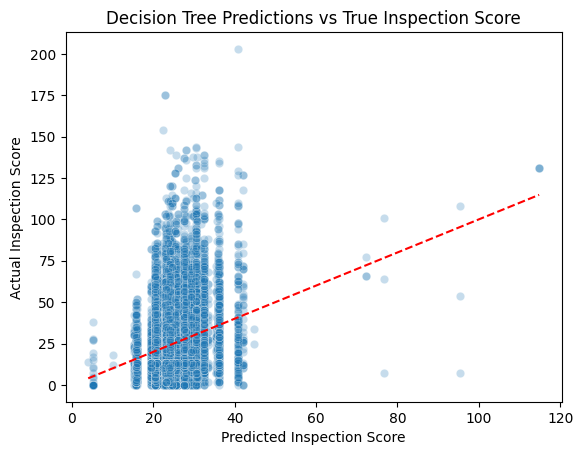

In [ ]:
# Predictions
model = DecisionTreeRegressor(
    max_depth=7,
    min_samples_leaf=1,
    random_state=3001,
    ccp_alpha = 0.1,
    max_features=None,
    min_samples_split=4
)

model.fit(X_train_alt, y_train_alt)

y_pred = model.predict(X_test_alt)

y_hat = model.predict(X_test_alt)

# Predicted vs Actual plot
sns.scatterplot(
    y=y_test_alt,
    x=y_pred,
    alpha=0.25
)
plt.title('Decision Tree Predictions vs True Inspection Score')
plt.xlabel('Predicted Inspection Score')
plt.ylabel('Actual Inspection Score')

x_min = min(y_hat)
x_max = max(y_hat)
plt.plot([x_min, x_max], [x_min, x_max], color='red', linestyle='--')
plt.show()

**Random Forest Regressor**

When looking at the Random Forest model, I will be investigating n_estimators, max_depth, min_samples_split, min_samples_leaf, and max_features. These are the same features that we looked at in the Decision Tree model, with the addition of n_estimators. N_estimators represents the number of trees we want in the model. We found that the best parameters were n_estimators: 100, min_samples_split: 2, min_samples_leaf: 1, max_depth: None

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [50,100],
    "max_depth": [None, 5],
    "min_samples_split": [2,5,9],
    "min_samples_leaf": [1,3,5]
}

# randomized search
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring={
        "r2": "r2",
        "rmse": "neg_root_mean_squared_error",
        "mse": "neg_mean_squared_error"
    },
    refit="rmse",
    random_state=3001,
    n_jobs=-1,
    verbose=2
)

# fit on training data only
random_search.fit(X_train_alt, y_train_alt)

# cross-validation results for the best sampled setting
print("Best params:", random_search.best_params_)
print("Best CV R^2:", random_search.cv_results_["mean_test_r2"][random_search.best_index_])
print("Best CV RMSE:", -random_search.cv_results_["mean_test_rmse"][random_search.best_index_])
print("Best CV MSE:", -random_search.cv_results_["mean_test_mse"][random_search.best_index_])

#"min_samples_leaf": [1,3,5],
#"max_features": ["sqrt", "log2", 1.0]

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': None}
Best CV R^2: 0.6318749141516454
Best CV RMSE: 11.397252749840575
Best CV MSE: 129.90254282387687


We see that this model has an R^2 of 0.63, a RMSE of 11.40, and a MSE of 129.90

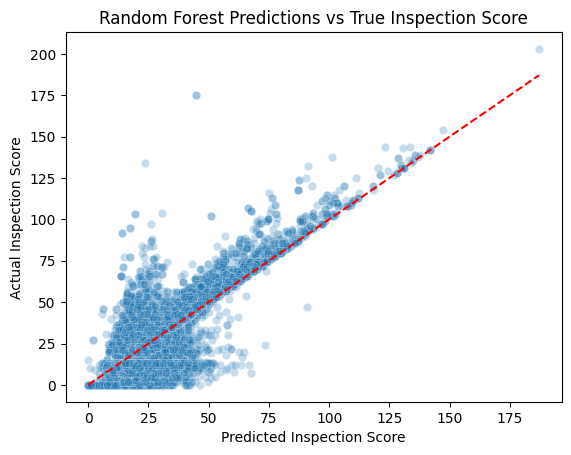

In [ ]:
# Predictions
model = random_search.best_estimator_

y_pred = model.predict(X_test_alt)

y_hat_rf = model.predict(X_test_alt)

# Predicted vs Actual plot
sns.scatterplot(
    y=y_test_alt,
    x=y_pred,
    alpha=0.25
)
plt.title('Random Forest Predictions vs True Inspection Score')
plt.xlabel('Predicted Inspection Score')
plt.ylabel('Actual Inspection Score')

x_min = min(y_hat_rf)
x_max = max(y_hat_rf)
plt.plot([x_min, x_max], [x_min, x_max], color='red', linestyle='--')
plt.show()

**Discussion**



After finding the best parameters for each of the models and finding their RMSE, MSE, and R^2, we were able to understand exactly how well our models were performing. The Linear Regression with the raw features and the Linear Regression with the feature regression did not perform well. They all had an R^2 of below 0.06, as well as higher MSE and RMSE values. The worst of all of them was the Linear Regression model with the raw features. It had the lowest metrics of all of the models (R^2:0.03, RMSE:18.56, MSE:344.45). Our best model was the KNN that had an R^2 of 0.66, an RMSE of 10.92, and an MSE of 119.18.  If we had more time, we could try to look through more of the parameters and expand the grid search. Because of the time needed to do such a computationally heavy procedure, we were only able to perform the grid search on the parameters that we did. We could also try to look for more variables that could help predict our model. Our R^2 was fairly low even for our highest model. This means that our model did not explain the variation in the data very well. Maybe looking at something like how long the restaurant has been around, management quality, kitchen conditions, and possibly including past inspection scores could help improve our model